# Predicting MP18 Formation Energies with ALIGNN

This notebook loads the pretrained **Atomistic Line Graph Neural Network (ALIGNN)** developed by Kamal Choudhary and Brian DeCost and applies it to structures from the **Materials Project 2018 (MP18)** dataset. ALIGNN passes messages over both an atomistic bond graph and its line graph, so the model represents bond distances and bond angles.

The official pretrained checkpoint used here is `mp_e_form_alignn`. Its output is the Materials Project PBE **formation energy per atom** in eV/atom. The MP18 data are distributed by JARVIS-Tools under the dataset name `megnet` and contain 69,239 structures.

Primary references:

- Choudhary, K. and DeCost, B., [*Atomistic Line Graph Neural Network for improved materials property predictions*](https://doi.org/10.1038/s41524-021-00650-1), npj Computational Materials 7, 185 (2021).
- [Official ALIGNN repository](https://github.com/usnistgov/alignn) and [pretrained-model registry](https://github.com/usnistgov/alignn/blob/main/alignn/pretrained.py).
- [JARVIS-Tools database documentation](https://jarvis-tools.readthedocs.io/en/master/databases.html).
- [ALIGNN model artifacts on Figshare](https://figshare.com/projects/ALIGNN_models/126478).


## Scientific scope

The model predicts the DFT formation energy used in MP18. This is often discussed as a zero-temperature approximation to formation enthalpy, but it is **not** a finite-temperature experimental standard enthalpy: thermal, zero-point, pressure-volume, and DFT reference corrections are not added here. The native and most defensible reported quantity is therefore eV/atom.

For convenience, the notebook also converts the prediction to eV per reduced formula unit and kJ/mol of reduced formula units using $1\;\mathrm{eV/particle}=96.48533212\;\mathrm{kJ/mol}$. Treat that conversion as a change of units, not as an addition of missing thermodynamic corrections.

The default run predicts a reproducible sample so the notebook remains practical on a CPU. Set `PREDICTION_LIMIT = None` below to process all 69,239 MP18 structures. Summary errors over the default sample are descriptive only because the sample can contain training, validation, and test structures; they are not a held-out benchmark score.


## 1. Environment

The historical MP18 checkpoint uses the legacy DGL implementation of ALIGNN. A dedicated Python 3.10 environment is the least fragile setup. One reproducible option is:

```bash
conda create -n alignn-mp18 -c conda-forge python=3.10 alignn=2024.12.12 jupyterlab
conda activate alignn-mp18
jupyter lab
```

If installing with `pip`, use a DGL build compatible with the installed PyTorch version and keep NumPy below version 2 for the legacy compiled stack. Restart the kernel after changing packages. The first execution needs internet access to download both MP18 and the pretrained model; JARVIS and ALIGNN cache them for later runs.


In [61]:
# If this kernel is a fresh compatible environment, uncomment, run once,
# and restart the kernel before continuing. Conda is preferred for DGL.
# %pip install "numpy==1.26.4" "torch==2.2.1" "torchdata==0.7.1" "dgl==2.1.0" "alignn==2024.12.12" "jarvis-tools==2024.10.30" pandas matplotlib tqdm
# %pip install "oxford-loss-landscapes @ git+https://github.com/TRustworthy-AI-Tools-for-Science/oxford-loss-landscapes.git@77b05b5b3845117abc7ad6b0df5950ecdd507826"


In [62]:
from collections import Counter
import ast
import hashlib
from importlib.metadata import version
from pathlib import Path
import json
import os
import platform
import zipfile

# Avoid a first-import write to ~/.dgl and make the backend explicit.
os.environ.setdefault("DGLBACKEND", "pytorch")

import dgl
import matplotlib.pyplot as plt
import numpy as np
import oxford_loss_landscapes as oll
import pandas as pd
import requests
import torch
from tqdm.auto import tqdm

from alignn.graphs import Graph
from alignn.pretrained import get_all_models, get_figshare_model
from jarvis.core.atoms import Atoms
from jarvis.db.figshare import data
from jarvis.db.jsonutils import loadjson
from oxford_loss_landscapes.metrics import Metric

print({
    "python": platform.python_version(),
    "torch": torch.__version__,
    "dgl": dgl.__version__,
    "alignn": version("alignn"),
    "jarvis-tools": version("jarvis-tools"),
    "oxford-loss-landscapes": version("oxford-loss-landscapes"),
    "device available": "cuda" if torch.cuda.is_available() else "cpu",
})

{'python': '3.11.16', 'torch': '2.2.1', 'dgl': '2.1.0', 'alignn': '2024.12.12', 'jarvis-tools': '2024.10.30', 'oxford-loss-landscapes': '0.1.0.dev1+g77b05b5b3', 'device available': 'cpu'}


## 2. Configuration

There are three selection modes:

1. Put one or more exact Materials Project identifiers in `MP_IDS`.
2. Leave `MP_IDS` empty and set an integer `PREDICTION_LIMIT` for a reproducible random sample.
3. Leave `MP_IDS` empty and set `PREDICTION_LIMIT = None` for all MP18 records.

If MP18 was downloaded separately, set `LOCAL_MP18_JSON` to the extracted `megnet.json`; otherwise JARVIS-Tools downloads and caches it.


In [63]:
MODEL_NAME = "mp_e_form_alignn"
LOCAL_MP18_JSON = None  # Example: Path("/path/to/megnet.json")

MP_IDS = []             # Example: ["mp-149", "mp-2534"]
PREDICTION_LIMIT = 64   # Set to None to predict every MP18 structure
RANDOM_SEED = 420

CUTOFF_ANGSTROM = 8.0
MAX_NEIGHBORS = 12
BATCH_SIZE = 16 if torch.cuda.is_available() else 4

ROBUSTNESS_STRUCTURE_LIMIT = 12
ATOMIC_DISPLACEMENT_MAGNITUDES_ANGSTROM = np.array([0.005, 0.01, 0.02, 0.05, 0.10])
ATOMIC_DISPLACEMENT_DIRECTIONS = 5
STRAIN_MAGNITUDES = np.array([0.001, 0.0025, 0.005, 0.01, 0.02])
MINIMUM_DISTANCE_RATIO = 0.70
PUBLISHED_MP18_MAE_EV_ATOM = 0.022
ROBUSTNESS_OUTPUT_DIR = Path("alignn_mp18_robustness")
LOSS_LANDSCAPE_STRUCTURE_LIMIT = 12
LOSS_LANDSCAPE_DISTANCE = 0.02  # total plane width: approximately +/-1% in model-norm units
LOSS_LANDSCAPE_STEPS = 10       # even so the sampled grid contains the pretrained model exactly
LOSS_LANDSCAPE_SEED = RANDOM_SEED + 1
LOSS_LANDSCAPE_NORMALIZATION = "filter"

# Li et al. (2023) MP21-only alloys-of-interest (AoI) analysis.
AOI_MP21_ROBUSTNESS_LIMIT = 32
AOI_MP21_PARAMETER_LANDSCAPE_LIMIT = LOSS_LANDSCAPE_STRUCTURE_LIMIT
AOI_PARAMETER_LANDSCAPE_STEPS = LOSS_LANDSCAPE_STEPS
AOI_PARAMETER_LANDSCAPE_SEED = LOSS_LANDSCAPE_SEED  # same random plane as MP18
AOI_DATA_URL = "https://zenodo.org/api/records/7659267/files/data.zip/content"
AOI_DATA_ARCHIVE_SIZE = 151_889_864
AOI_DATA_ARCHIVE_MD5 = "524f29d7bcacdeee4ed980ad330875bd"
AOI_DATA_CACHE_DIR = Path.home() / ".cache" / "mse420-ai-forensics" / "li_2023_aoi"
LOCAL_AOI_DATA_ZIP = None  # Optional path to an already-downloaded data.zip

SAVE_RESULTS = True
OUTPUT_PATH = Path("alignn_mp18_formation_energy_predictions.csv")
EV_PER_PARTICLE_TO_KJ_PER_MOL = 96.48533212

## 3. Load MP18

JARVIS-Tools calls this dataset `megnet` because it is the Materials Project snapshot used in the MEGNet work. In the ALIGNN paper it is reported as the Materials Project 2018 dataset, with 60,000/5,000/4,239 train/validation/test structures. The target field is `e_form` in eV/atom.


In [64]:
if LOCAL_MP18_JSON is None:
    mp18 = data("megnet")
else:
    local_path = Path(LOCAL_MP18_JSON).expanduser().resolve()
    if not local_path.exists():
        raise FileNotFoundError(f"MP18 JSON was not found: {local_path}")
    mp18 = loadjson(str(local_path))

if not isinstance(mp18, list) or not mp18:
    raise ValueError("Expected MP18 to be a non-empty list of records.")

required_fields = {"atoms", "e_form"}
missing_fields = required_fields - set(mp18[0])
if missing_fields:
    raise KeyError(f"Unexpected MP18 schema; missing fields: {sorted(missing_fields)}")

def mp_identifier(record, fallback_index=None):
    identifier = record.get("id", record.get("jid"))
    return str(identifier) if identifier is not None else f"record-{fallback_index}"

print(f"Loaded {len(mp18):,} MP18 structures.")
print(f"Record fields: {sorted(mp18[0].keys())}")


Obtaining MEGNET-3D CFID dataset 69k...
Reference:https://pubs.acs.org/doi/10.1021/acs.chemmater.9b01294
Loading the zipfile...
Loading completed.
Loaded 69,239 MP18 structures.
Record fields: ['atoms', 'bulk modulus', 'desc', 'e_form', 'e_hull', 'elastic anisotropy', 'formula', 'gap pbe', 'id', 'mu_b', 'shear modulus']


In [65]:
preview_rows = []
for index, record in enumerate(mp18[:5]):
    atoms = Atoms.from_dict(record["atoms"])
    preview_rows.append({
        "mp_id": mp_identifier(record, index),
        "formula": atoms.composition.reduced_formula,
        "atoms_in_cell": atoms.num_atoms,
        "reference_e_form_eV_atom": float(np.asarray(record["e_form"]).reshape(-1)[0]),
    })
pd.DataFrame(preview_rows)


,mp_id,formula,atoms_in_cell,reference_e_form_eV_atom
0,mp-10,As,2,0.107405
1,mp-100,Hf,1,0.181111
2,mp-1000,BaTe,2,-1.790168
3,mp-10000,Hf2S,6,-1.253224
4,mp-10003,Nb4CoSi,12,-0.343178


## 4. Load the pretrained ALIGNN model

`get_figshare_model` downloads the official archive on first use, reconstructs the architecture from the saved configuration, loads the checkpoint, moves it to CUDA when available (otherwise CPU), and switches it to evaluation mode. Loading happens once here rather than once per crystal.


In [66]:
available_models = get_all_models()
if MODEL_NAME not in available_models:
    raise KeyError(
        f"{MODEL_NAME!r} is not present in this ALIGNN installation. "
        "Install the pinned legacy version shown above."
    )

model_url, output_count, *_ = available_models[MODEL_NAME]
print(f"Checkpoint: {MODEL_NAME}")
print(f"Artifact URL: {model_url}")
print(f"Model outputs: {output_count}")

model = get_figshare_model(MODEL_NAME)
model.eval()
model_device = next(model.parameters()).device
parameter_count = sum(parameter.numel() for parameter in model.parameters())
print(f"Loaded {parameter_count:,} parameters on {model_device}.")


Checkpoint: mp_e_form_alignn
Artifact URL: https://figshare.com/ndownloader/files/31458811
Model outputs: 1
Using chk file mp_e_form_alignnn/checkpoint_300.pt from  ['mp_e_form_alignnn/checkpoint_300.pt']
Path /Users/jae3goals/anaconda3/envs/mse420-ai-forensics/lib/python3.11/site-packages/alignn/mp_e_form_alignn.zip
Config /Users/jae3goals/Jupyter Code on Root/MSE420 AI Forensics/demonstrations/mp_e_form_alignnn/config.json
Loaded 4,026,753 parameters on cpu.


## 5. Select MP18 structures

Exact identifiers take precedence over the random/full-dataset control. Random indices are sorted after sampling so results retain their original MP18 order.


In [67]:
id_to_index = {mp_identifier(record, index): index for index, record in enumerate(mp18)}

if MP_IDS:
    missing_ids = sorted(set(MP_IDS) - set(id_to_index))
    if missing_ids:
        raise KeyError(f"MP identifiers not found in MP18: {missing_ids}")
    selected_indices = np.array([id_to_index[identifier] for identifier in MP_IDS], dtype=int)
elif PREDICTION_LIMIT is None or PREDICTION_LIMIT >= len(mp18):
    selected_indices = np.arange(len(mp18), dtype=int)
else:
    if not isinstance(PREDICTION_LIMIT, int) or PREDICTION_LIMIT < 1:
        raise ValueError("PREDICTION_LIMIT must be a positive integer or None.")
    rng = np.random.default_rng(RANDOM_SEED)
    selected_indices = np.sort(
        rng.choice(len(mp18), size=PREDICTION_LIMIT, replace=False)
    )

selected_records = [mp18[index] for index in selected_indices]
print(f"Selected {len(selected_records):,} of {len(mp18):,} MP18 structures.")


Selected 64 of 69,239 MP18 structures.


## 6. Build atomistic and line graphs, then predict

The graph settings below match the official pretrained prediction defaults for solids: an 8 Å cutoff and up to 12 neighbors. DGL combines each small group of variable-sized crystal graphs into one batch. No gradients are retained during inference.


In [68]:
def graph_inputs_from_atoms(atoms):
    """Convert a JARVIS Atoms object to ALIGNN graph inputs."""
    graph, line_graph = Graph.atom_dgl_multigraph(
        atoms,
        cutoff=CUTOFF_ANGSTROM,
        max_neighbors=MAX_NEIGHBORS,
    )
    lattice = torch.as_tensor(atoms.lattice_mat, dtype=torch.float32)
    return graph, line_graph, lattice


def graph_inputs(record):
    """Convert one MP18 record to the two ALIGNN graphs and its lattice."""
    atoms = Atoms.from_dict(record["atoms"])
    graph, line_graph, lattice = graph_inputs_from_atoms(atoms)
    return atoms, graph, line_graph, lattice


def graph_observables(graph, line_graph):
    """Record graph and neighbor-shell diagnostics before moving graphs to the device."""
    source, destination = graph.edges()
    source = source.detach().cpu().numpy().astype(int)
    destination = destination.detach().cpu().numpy().astype(int)
    distances = torch.linalg.vector_norm(graph.edata["r"], dim=1).detach().cpu().numpy()
    positive_distances = distances[distances > 1e-8]
    neighbor_counts = np.bincount(source, minlength=graph.num_nodes())
    neighbor_boundaries = np.array([
        distances[source == node].max() if np.any(source == node) else np.nan
        for node in range(graph.num_nodes())
    ])
    edge_multiset = tuple(sorted(Counter(zip(source.tolist(), destination.tolist())).items()))
    return {
        "graph_nodes": int(graph.num_nodes()),
        "graph_edges": int(graph.num_edges()),
        "line_graph_edges": int(line_graph.num_edges()),
        "min_periodic_distance_angstrom": (
            float(positive_distances.min()) if len(positive_distances) else np.nan
        ),
        "mean_neighbors_per_atom": float(neighbor_counts.mean()),
        "max_neighbors_per_atom_observed": int(neighbor_counts.max()),
        "mean_selected_neighbor_boundary_angstrom": float(np.nanmean(neighbor_boundaries)),
        "max_selected_neighbor_boundary_angstrom": float(np.nanmax(neighbor_boundaries)),
        "_edge_multiset": edge_multiset,
    }


def edge_multiset_jaccard(first, second):
    """Multiset Jaccard score for directed atom-index pairs in two graphs."""
    first, second = dict(first), dict(second)
    keys = set(first) | set(second)
    union = sum(max(first.get(key, 0), second.get(key, 0)) for key in keys)
    intersection = sum(min(first.get(key, 0), second.get(key, 0)) for key in keys)
    return float(intersection / union) if union else 1.0


def evaluate_atom_structures(atoms_list, batch_size=BATCH_SIZE):
    """Run ALIGNN and retain graph/structure observables for every structure."""
    evaluations = []
    for start in range(0, len(atoms_list), batch_size):
        atoms_batch = atoms_list[start : start + batch_size]
        prepared = [graph_inputs_from_atoms(atoms) for atoms in atoms_batch]
        graphs, line_graphs, lattices = zip(*prepared)
        diagnostics = [
            graph_observables(graph, line_graph)
            for graph, line_graph in zip(graphs, line_graphs)
        ]
        with torch.inference_mode():
            prediction = model([
                dgl.batch(list(graphs)).to(model_device),
                dgl.batch(list(line_graphs)).to(model_device),
                torch.stack(list(lattices)).to(model_device),
            ])
        prediction = prediction.detach().cpu().numpy().reshape(-1)
        if len(prediction) != len(atoms_batch):
            raise RuntimeError(f"Expected {len(atoms_batch)} outputs, received {len(prediction)}.")
        for atoms, predicted_value, diagnostic in zip(atoms_batch, prediction, diagnostics):
            evaluations.append({
                "atoms": atoms,
                "prediction_eV_atom": float(predicted_value),
                "volume_angstrom3": float(abs(np.linalg.det(np.asarray(atoms.lattice_mat)))),
                "density_g_cm3": float(atoms.density),
                **diagnostic,
            })
    return evaluations


def make_fractional_atoms(lattice, fractional_coordinates, elements):
    return Atoms(
        lattice_mat=np.asarray(lattice, dtype=float),
        coords=np.mod(np.asarray(fractional_coordinates, dtype=float), 1.0),
        elements=list(elements),
        cartesian=False,
    )


def perturbation_row(
    record, dataset_index, baseline, perturbed, *, family, perturbation_type,
    magnitude, signed_magnitude, magnitude_unit, replicate=0, seed=np.nan,
    direction_id=None, topology_comparable=True, status="ok", extra=None,
):
    """Create one plotting-ready row with prediction, structure, and graph changes."""
    atoms = baseline["atoms"]
    reference = float(np.asarray(record["e_form"]).reshape(-1)[0])
    baseline_prediction = baseline["prediction_eV_atom"]
    row = {
        "perturbation_family": family,
        "perturbation_type": perturbation_type,
        "magnitude": float(magnitude),
        "signed_magnitude": float(signed_magnitude),
        "magnitude_unit": magnitude_unit,
        "replicate": int(replicate),
        "seed": seed,
        "direction_id": direction_id,
        "result_status": status,
        "mp18_index": int(dataset_index),
        "mp_id": mp_identifier(record, int(dataset_index)),
        "formula": atoms.composition.reduced_formula,
        "atoms_in_baseline_cell": int(atoms.num_atoms),
        "reference_e_form_eV_atom": reference,
        "baseline_prediction_eV_atom": baseline_prediction,
        "baseline_error_eV_atom": baseline_prediction - reference,
        "baseline_volume_angstrom3": baseline["volume_angstrom3"],
        "baseline_density_g_cm3": baseline["density_g_cm3"],
        "baseline_min_distance_angstrom": baseline["min_periodic_distance_angstrom"],
        "baseline_graph_nodes": baseline["graph_nodes"],
        "baseline_graph_edges": baseline["graph_edges"],
        "baseline_line_graph_edges": baseline["line_graph_edges"],
        "baseline_mean_neighbors_per_atom": baseline["mean_neighbors_per_atom"],
        "baseline_neighbor_boundary_angstrom": baseline["mean_selected_neighbor_boundary_angstrom"],
        "topology_comparable": bool(topology_comparable),
    }
    if perturbed is None:
        row.update({
            "perturbed_prediction_eV_atom": np.nan,
            "delta_prediction_eV_atom": np.nan,
            "absolute_delta_prediction_eV_atom": np.nan,
            "absolute_delta_over_published_mae": np.nan,
            "perturbed_error_using_baseline_label_eV_atom": np.nan,
            "prediction_sign_changed": False,
            "structural_valid": False,
        })
    else:
        prediction = perturbed["prediction_eV_atom"]
        delta = prediction - baseline_prediction
        min_distance_ratio = (
            perturbed["min_periodic_distance_angstrom"]
            / baseline["min_periodic_distance_angstrom"]
        )
        comparable = bool(
            topology_comparable and baseline["graph_nodes"] == perturbed["graph_nodes"]
        )
        jaccard = (
            edge_multiset_jaccard(baseline["_edge_multiset"], perturbed["_edge_multiset"])
            if comparable else np.nan
        )
        row.update({
            "atoms_in_perturbed_cell": int(perturbed["atoms"].num_atoms),
            "perturbed_prediction_eV_atom": prediction,
            "delta_prediction_eV_atom": delta,
            "absolute_delta_prediction_eV_atom": abs(delta),
            "absolute_delta_over_published_mae": abs(delta) / PUBLISHED_MP18_MAE_EV_ATOM,
            "perturbed_error_using_baseline_label_eV_atom": prediction - reference,
            "prediction_sign_changed": bool(np.signbit(prediction) != np.signbit(baseline_prediction)),
            "perturbed_volume_angstrom3": perturbed["volume_angstrom3"],
            "volume_ratio": perturbed["volume_angstrom3"] / baseline["volume_angstrom3"],
            "perturbed_density_g_cm3": perturbed["density_g_cm3"],
            "density_ratio": perturbed["density_g_cm3"] / baseline["density_g_cm3"],
            "perturbed_min_distance_angstrom": perturbed["min_periodic_distance_angstrom"],
            "min_distance_ratio": min_distance_ratio,
            "structural_valid": bool(
                perturbed["volume_angstrom3"] > 0 and min_distance_ratio >= MINIMUM_DISTANCE_RATIO
            ),
            "perturbed_graph_nodes": perturbed["graph_nodes"],
            "perturbed_graph_edges": perturbed["graph_edges"],
            "graph_edge_count_change": perturbed["graph_edges"] - baseline["graph_edges"],
            "perturbed_line_graph_edges": perturbed["line_graph_edges"],
            "line_graph_edge_count_change": (
                perturbed["line_graph_edges"] - baseline["line_graph_edges"]
            ),
            "perturbed_mean_neighbors_per_atom": perturbed["mean_neighbors_per_atom"],
            "perturbed_neighbor_boundary_angstrom": (
                perturbed["mean_selected_neighbor_boundary_angstrom"]
            ),
            "edge_multiset_jaccard": jaccard,
            "topology_changed": bool(comparable and jaccard < 1.0 - 1e-12),
        })
    if extra:
        row.update(extra)
    return row


def atoms_per_reduced_formula(atoms):
    reduced_counts, _ = atoms.composition.reduce()
    return int(sum(reduced_counts.values()))


def predict_mp18(records, original_indices, batch_size=BATCH_SIZE):
    """Predict formation energy for records while loading the model only once."""
    rows = []
    starts = range(0, len(records), batch_size)
    for start in tqdm(starts, total=(len(records) + batch_size - 1) // batch_size):
        stop = min(start + batch_size, len(records))
        batch_records = records[start:stop]
        prepared = [graph_inputs(record) for record in batch_records]
        atoms_batch, graphs, line_graphs, lattices = zip(*prepared)

        batched_graph = dgl.batch(list(graphs)).to(model_device)
        batched_line_graph = dgl.batch(list(line_graphs)).to(model_device)
        batched_lattice = torch.stack(list(lattices)).to(model_device)

        with torch.inference_mode():
            prediction = model(
                [batched_graph, batched_line_graph, batched_lattice]
            )
        prediction = prediction.detach().cpu().numpy().reshape(-1)
        if len(prediction) != len(batch_records):
            raise RuntimeError(
                f"Expected {len(batch_records)} outputs, received {len(prediction)}."
            )

        for offset, (record, atoms, predicted_e_form) in enumerate(
            zip(batch_records, atoms_batch, prediction)
        ):
            dataset_index = int(original_indices[start + offset])
            reference_e_form = float(np.asarray(record["e_form"]).reshape(-1)[0])
            formula_atom_count = atoms_per_reduced_formula(atoms)
            predicted_e_form = float(predicted_e_form)
            predicted_e_form_formula = predicted_e_form * formula_atom_count
            rows.append({
                "mp18_index": dataset_index,
                "mp_id": mp_identifier(record, dataset_index),
                "formula": atoms.composition.reduced_formula,
                "atoms_in_crystal_cell": atoms.num_atoms,
                "atoms_in_reduced_formula": formula_atom_count,
                "reference_e_form_eV_atom": reference_e_form,
                "predicted_e_form_eV_atom": predicted_e_form,
                "error_eV_atom": predicted_e_form - reference_e_form,
                "predicted_e_form_eV_formula": predicted_e_form_formula,
                "approx_formation_enthalpy_kJ_mol_formula": (
                    predicted_e_form_formula * EV_PER_PARTICLE_TO_KJ_PER_MOL
                ),
            })
    return pd.DataFrame(rows)


In [69]:
results = predict_mp18(selected_records, selected_indices)

# Use a compact, reproducible subset spanning the selected formation-energy range.
robustness_count = min(ROBUSTNESS_STRUCTURE_LIMIT, len(selected_records))
reference_values = np.array([float(np.asarray(record["e_form"]).reshape(-1)[0]) for record in selected_records])
energy_order = np.argsort(reference_values)
robustness_positions = energy_order[np.linspace(0, len(energy_order) - 1, robustness_count, dtype=int)]
robustness_records = [selected_records[position] for position in robustness_positions]
robustness_indices = [int(selected_indices[position]) for position in robustness_positions]
robustness_atoms = [Atoms.from_dict(record["atoms"]) for record in robustness_records]
robustness_baselines = evaluate_atom_structures(robustness_atoms)

print(f"Robustness experiments will use {robustness_count} structures spanning the selected label range.")
results.head(10).round(5)


  0%|          | 0/16 [00:00<?, ?it/s]

Robustness experiments will use 12 structures spanning the selected label range.


,mp18_index,mp_id,formula,atoms_in_crystal_cell,atoms_in_reduced_formula,reference_e_form_eV_atom,predicted_e_form_eV_atom,error_eV_atom,predicted_e_form_eV_formula,approx_formation_enthalpy_kJ_mol_formula
0,944,mp-1017563,GaPt3C,5,5,0.34045,0.34228,0.00183,1.71141,165.12590
1,1327,mp-1018952,PrZnIn,6,3,-0.45053,-0.45416,-0.00363,-1.36247,-131.45869
2,1626,mp-1020145,Na2GeS6O21,120,30,-2.01295,-2.01775,-0.00480,-60.53257,-5840.50534
3,2584,mp-1027634,TeMoWS3,12,6,-0.92815,-0.93180,-0.00365,-5.59078,-539.42834
4,3396,mp-10785,RbLuSe2,4,4,-1.70566,-1.70680,-0.00113,-6.82719,-658.72355
5,4542,mp-12647,TbNbO4,12,6,-3.58493,-3.58672,-0.00179,-21.52034,-2076.39756
6,5835,mp-15322,ScSiCu,9,3,-0.66713,-0.66584,0.00129,-1.99752,-192.73139
7,6296,mp-16365,SnSb,2,2,0.18738,0.18534,-0.00204,0.37068,35.76494
8,6963,mp-1769,SbPd,4,2,-0.44080,-0.44381,-0.00301,-0.88762,-85.64236
9,8251,mp-19457,V6O13,38,19,-2.40204,-2.40398,-0.00194,-45.67562,-4407.02740


## 7. Robustness experiments: controlled perturbations

The following three cells test distinct failure modes. Each emits a tidy table with one row per structure/perturbation, retains both predictions, records structural and graph changes, and optionally writes CSV files plus a machine-readable experiment manifest. The MP18 reference label is repeated for context only: after a physical perturbation it is no longer the DFT label of the modified structure.

The exact-invariance tests should ideally produce zero prediction change. Coordinate noise uses zero-centroid Cartesian displacement directions normalized to the requested RMS amplitude. Lattice tests keep fractional coordinates fixed and apply small symmetric deformation tensors. A row is marked structurally valid when its volume remains positive and its minimum periodic separation is at least 70% of the baseline value.


In [70]:
# Perturbation 1: transformations under which an intensive crystal prediction should be invariant.
invariance_rows = []
invariance_jobs = []

for record, dataset_index, atoms, baseline in zip(
    robustness_records, robustness_indices, robustness_atoms, robustness_baselines
):
    invariance_rows.append(perturbation_row(
        record, dataset_index, baseline, baseline,
        family="exact_invariance", perturbation_type="baseline",
        magnitude=0.0, signed_magnitude=0.0, magnitude_unit="none",
        direction_id="baseline", extra={"transformation_definition": "identity"},
    ))
    seed = int(np.random.SeedSequence([RANDOM_SEED, 100_000, dataset_index]).generate_state(1)[0])
    rng = np.random.default_rng(seed)
    fractional = np.asarray(atoms.frac_coords)
    lattice = np.asarray(atoms.lattice_mat)
    elements = list(atoms.elements)

    permutation = rng.permutation(atoms.num_atoms)
    invariance_jobs.append({
        "record": record, "dataset_index": dataset_index, "baseline": baseline,
        "atoms": make_fractional_atoms(lattice, fractional[permutation], np.asarray(elements)[permutation]),
        "perturbation_type": "atom_permutation", "seed": seed,
        "direction_id": "random_permutation", "topology_comparable": False,
        "extra": {
            "transformation_definition": "reorder atoms without changing species or coordinates",
            "permutation": json.dumps(permutation.tolist()),
        },
    })

    translation = rng.uniform(0.0, 1.0, size=3)
    invariance_jobs.append({
        "record": record, "dataset_index": dataset_index, "baseline": baseline,
        "atoms": make_fractional_atoms(lattice, fractional + translation, elements),
        "perturbation_type": "fractional_translation", "seed": seed,
        "direction_id": "random_fractional_shift", "topology_comparable": True,
        "extra": {
            "transformation_definition": "translate every atom by the same fractional vector and wrap",
            "translation_fractional_a": translation[0],
            "translation_fractional_b": translation[1],
            "translation_fractional_c": translation[2],
        },
    })

    rotation, _ = np.linalg.qr(rng.normal(size=(3, 3)))
    if np.linalg.det(rotation) < 0:
        rotation[:, 0] *= -1
    invariance_jobs.append({
        "record": record, "dataset_index": dataset_index, "baseline": baseline,
        "atoms": make_fractional_atoms(lattice @ rotation.T, fractional, elements),
        "perturbation_type": "rigid_rotation", "seed": seed,
        "direction_id": "random_proper_rotation", "topology_comparable": True,
        "extra": {
            "transformation_definition": "rotate lattice and Cartesian coordinates by one SO(3) matrix",
            "rotation_matrix": json.dumps(rotation.tolist()),
            "rotation_determinant": float(np.linalg.det(rotation)),
        },
    })

    invariance_jobs.append({
        "record": record, "dataset_index": dataset_index, "baseline": baseline,
        "atoms": atoms.make_supercell([2, 1, 1]),
        "perturbation_type": "supercell_2x1x1", "seed": np.nan,
        "direction_id": "a_axis_replication", "topology_comparable": False,
        "extra": {
            "transformation_definition": "represent the same infinite crystal as a 2 x 1 x 1 supercell",
            "supercell_a": 2, "supercell_b": 1, "supercell_c": 1,
        },
    })

invariance_evaluations = evaluate_atom_structures([job["atoms"] for job in invariance_jobs])
for job, perturbed in zip(invariance_jobs, invariance_evaluations):
    invariance_rows.append(perturbation_row(
        job["record"], job["dataset_index"], job["baseline"], perturbed,
        family="exact_invariance", perturbation_type=job["perturbation_type"],
        magnitude=1.0, signed_magnitude=1.0, magnitude_unit="transformation",
        seed=job["seed"], direction_id=job["direction_id"],
        topology_comparable=job["topology_comparable"], extra=job["extra"],
    ))

invariance_results = pd.DataFrame(invariance_rows).sort_values(["mp18_index", "perturbation_type"])
robustness_manifest = {
    "model": MODEL_NAME,
    "random_seed": RANDOM_SEED,
    "graph_cutoff_angstrom": CUTOFF_ANGSTROM,
    "graph_max_neighbors": MAX_NEIGHBORS,
    "published_mp18_mae_eV_atom": PUBLISHED_MP18_MAE_EV_ATOM,
    "structural_validity_minimum_distance_ratio": MINIMUM_DISTANCE_RATIO,
    "robustness_mp18_indices": robustness_indices,
    "atomic_displacement_magnitudes_angstrom": ATOMIC_DISPLACEMENT_MAGNITUDES_ANGSTROM.tolist(),
    "atomic_displacement_directions": ATOMIC_DISPLACEMENT_DIRECTIONS,
    "strain_magnitudes": STRAIN_MAGNITUDES.tolist(),
    "methods": {
        "exact_invariance": ["atom permutation", "wrapped fractional translation", "proper rigid rotation", "2x1x1 supercell"],
        "coordinate_noise": "zero-centroid Gaussian Cartesian directions, normalized to requested RMS displacement",
        "lattice_strain": "symmetric small-strain deformation with fixed fractional coordinates",
    },
}
if SAVE_RESULTS:
    ROBUSTNESS_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    invariance_results.to_csv(ROBUSTNESS_OUTPUT_DIR / "exact_invariance.csv", index=False)
    (ROBUSTNESS_OUTPUT_DIR / "experiment_manifest.json").write_text(
        json.dumps(robustness_manifest, indent=2) + "\n"
    )

invariance_results.groupby("perturbation_type").agg(
    samples=("absolute_delta_prediction_eV_atom", "size"),
    median_abs_delta_eV_atom=("absolute_delta_prediction_eV_atom", "median"),
    max_abs_delta_eV_atom=("absolute_delta_prediction_eV_atom", "max"),
    minimum_topology_jaccard=("edge_multiset_jaccard", "min"),
).round(8)


,samples,median_abs_delta_eV_atom,max_abs_delta_eV_atom,minimum_topology_jaccard
perturbation_type,,,,
atom_permutation,12,0.000000e+00,1.200000e-07,NaN
baseline,12,0.000000e+00,0.000000e+00,1.000000
fractional_translation,12,1.500000e-07,2.529620e-03,0.928571
rigid_rotation,12,7.500000e-07,2.671960e-03,0.857143
supercell_2x1x1,12,4.800000e-07,1.006490e-02,NaN


In [71]:
# Perturbation 2: small, zero-centroid Cartesian coordinate displacements.
coordinate_rows = []
coordinate_jobs = []

for record, dataset_index, atoms, baseline in zip(
    robustness_records, robustness_indices, robustness_atoms, robustness_baselines
):
    lattice = np.asarray(atoms.lattice_mat)
    for replicate in range(ATOMIC_DISPLACEMENT_DIRECTIONS):
        seed = int(np.random.SeedSequence([RANDOM_SEED, 200_000, dataset_index, replicate]).generate_state(1)[0])
        coordinate_rows.append(perturbation_row(
            record, dataset_index, baseline, baseline,
            family="coordinate_noise", perturbation_type="cartesian_displacement",
            magnitude=0.0, signed_magnitude=0.0, magnitude_unit="angstrom_rms",
            replicate=replicate, seed=seed, direction_id=f"gaussian_{replicate}",
            extra={"displacement_definition": "baseline; no displacement"},
        ))
        rng = np.random.default_rng(seed)
        direction = rng.normal(size=(atoms.num_atoms, 3))
        direction -= direction.mean(axis=0, keepdims=True)
        direction_rms = float(np.sqrt(np.mean(np.sum(direction**2, axis=1))))

        if direction_rms < 1e-12:
            for magnitude in ATOMIC_DISPLACEMENT_MAGNITUDES_ANGSTROM:
                coordinate_rows.append(perturbation_row(
                    record, dataset_index, baseline, None,
                    family="coordinate_noise", perturbation_type="cartesian_displacement",
                    magnitude=magnitude, signed_magnitude=magnitude, magnitude_unit="angstrom_rms",
                    replicate=replicate, seed=seed, direction_id=f"gaussian_{replicate}",
                    status="not_applicable_zero_internal_degrees_of_freedom",
                    extra={"displacement_definition": "zero-centroid Gaussian Cartesian displacement"},
                ))
            continue

        direction /= direction_rms
        for magnitude in ATOMIC_DISPLACEMENT_MAGNITUDES_ANGSTROM:
            displacement = float(magnitude) * direction
            displaced_cartesian = np.asarray(atoms.cart_coords) + displacement
            displaced_fractional = displaced_cartesian @ np.linalg.inv(lattice)
            coordinate_jobs.append({
                "record": record, "dataset_index": dataset_index, "baseline": baseline,
                "atoms": make_fractional_atoms(lattice, displaced_fractional, atoms.elements),
                "magnitude": float(magnitude), "replicate": replicate, "seed": seed,
                "direction_id": f"gaussian_{replicate}",
                "extra": {
                    "displacement_definition": "zero-centroid Gaussian Cartesian direction normalized to RMS=1",
                    "requested_rms_displacement_angstrom": float(magnitude),
                    "realized_rms_displacement_angstrom": float(np.sqrt(np.mean(np.sum(displacement**2, axis=1)))),
                    "maximum_displacement_angstrom": float(np.linalg.norm(displacement, axis=1).max()),
                    "net_displacement_angstrom": float(np.linalg.norm(displacement.sum(axis=0))),
                    "displacement_over_baseline_min_distance": float(magnitude) / baseline["min_periodic_distance_angstrom"],
                },
            })

coordinate_evaluations = evaluate_atom_structures([job["atoms"] for job in coordinate_jobs])
for job, perturbed in zip(coordinate_jobs, coordinate_evaluations):
    coordinate_rows.append(perturbation_row(
        job["record"], job["dataset_index"], job["baseline"], perturbed,
        family="coordinate_noise", perturbation_type="cartesian_displacement",
        magnitude=job["magnitude"], signed_magnitude=job["magnitude"],
        magnitude_unit="angstrom_rms", replicate=job["replicate"], seed=job["seed"],
        direction_id=job["direction_id"], topology_comparable=True, extra=job["extra"],
    ))

coordinate_noise_results = pd.DataFrame(coordinate_rows).sort_values(
    ["mp18_index", "replicate", "magnitude"]
)
if SAVE_RESULTS:
    ROBUSTNESS_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    coordinate_noise_results.to_csv(ROBUSTNESS_OUTPUT_DIR / "coordinate_noise.csv", index=False)

coordinate_noise_results.groupby("magnitude").agg(
    samples=("absolute_delta_prediction_eV_atom", "count"),
    median_abs_delta_eV_atom=("absolute_delta_prediction_eV_atom", "median"),
    p95_abs_delta_eV_atom=("absolute_delta_prediction_eV_atom", lambda values: values.quantile(0.95)),
    max_abs_delta_eV_atom=("absolute_delta_prediction_eV_atom", "max"),
    topology_change_rate=("topology_changed", "mean"),
    structural_valid_rate=("structural_valid", "mean"),
).round(8)


,samples,median_abs_delta_eV_atom,p95_abs_delta_eV_atom,max_abs_delta_eV_atom,topology_change_rate,structural_valid_rate
magnitude,,,,,,
0.000,60,0.000000,0.000000,0.000000,0.000000,1.0
0.005,60,0.000543,0.002580,0.007257,0.666667,1.0
0.010,60,0.000863,0.003056,0.006475,0.683333,1.0
0.020,60,0.002014,0.008962,0.018262,0.716667,1.0
0.050,60,0.008969,0.035836,0.042724,0.783333,1.0
0.100,60,0.031198,0.075645,0.092307,0.900000,1.0


In [72]:
# Perturbation 3: small lattice strains at fixed fractional coordinates.
strain_directions = {
    "isotropic": np.eye(3),
    "uniaxial_a": np.diag([1.0, 0.0, 0.0]),
    "uniaxial_b": np.diag([0.0, 1.0, 0.0]),
    "uniaxial_c": np.diag([0.0, 0.0, 1.0]),
    "orthorhombic_ab": np.diag([1.0, -1.0, 0.0]),
    "shear_ab": np.array([[0.0, 0.5, 0.0], [0.5, 0.0, 0.0], [0.0, 0.0, 0.0]]),
    "shear_ac": np.array([[0.0, 0.0, 0.5], [0.0, 0.0, 0.0], [0.5, 0.0, 0.0]]),
    "shear_bc": np.array([[0.0, 0.0, 0.0], [0.0, 0.0, 0.5], [0.0, 0.5, 0.0]]),
}
strain_rows = []
strain_jobs = []

for record, dataset_index, atoms, baseline in zip(
    robustness_records, robustness_indices, robustness_atoms, robustness_baselines
):
    lattice = np.asarray(atoms.lattice_mat)
    fractional = np.asarray(atoms.frac_coords)
    for strain_mode, unit_tensor in strain_directions.items():
        strain_rows.append(perturbation_row(
            record, dataset_index, baseline, baseline,
            family="lattice_strain", perturbation_type=strain_mode,
            magnitude=0.0, signed_magnitude=0.0, magnitude_unit="strain_fraction",
            direction_id=strain_mode, extra={
                "strain_definition": "baseline; identity deformation",
                "strain_xx": 0.0, "strain_yy": 0.0, "strain_zz": 0.0,
                "strain_xy": 0.0, "strain_xz": 0.0, "strain_yz": 0.0,
                "strain_trace": 0.0, "strain_frobenius_norm": 0.0,
                "deformation_determinant": 1.0,
            },
        ))
        for magnitude in STRAIN_MAGNITUDES:
            for sign in (-1.0, 1.0):
                signed_magnitude = sign * float(magnitude)
                strain_tensor = signed_magnitude * unit_tensor
                deformation = np.eye(3) + strain_tensor
                perturbed_lattice = lattice @ deformation.T
                strain_jobs.append({
                    "record": record, "dataset_index": dataset_index, "baseline": baseline,
                    "atoms": make_fractional_atoms(perturbed_lattice, fractional, atoms.elements),
                    "strain_mode": strain_mode, "magnitude": float(magnitude),
                    "signed_magnitude": signed_magnitude,
                    "extra": {
                        "strain_definition": "symmetric small-strain tensor; fractional coordinates fixed",
                        "strain_xx": strain_tensor[0, 0], "strain_yy": strain_tensor[1, 1],
                        "strain_zz": strain_tensor[2, 2], "strain_xy": strain_tensor[0, 1],
                        "strain_xz": strain_tensor[0, 2], "strain_yz": strain_tensor[1, 2],
                        "strain_trace": float(np.trace(strain_tensor)),
                        "strain_frobenius_norm": float(np.linalg.norm(strain_tensor)),
                        "deformation_determinant": float(np.linalg.det(deformation)),
                    },
                })

strain_evaluations = evaluate_atom_structures([job["atoms"] for job in strain_jobs])
for job, perturbed in zip(strain_jobs, strain_evaluations):
    strain_rows.append(perturbation_row(
        job["record"], job["dataset_index"], job["baseline"], perturbed,
        family="lattice_strain", perturbation_type=job["strain_mode"],
        magnitude=job["magnitude"], signed_magnitude=job["signed_magnitude"],
        magnitude_unit="strain_fraction", direction_id=job["strain_mode"],
        topology_comparable=True, extra=job["extra"],
    ))

lattice_strain_results = pd.DataFrame(strain_rows).sort_values(
    ["mp18_index", "perturbation_type", "signed_magnitude"]
)
perturbation_results = pd.concat(
    [invariance_results, coordinate_noise_results, lattice_strain_results],
    ignore_index=True, sort=False,
)

column_descriptions = {
    "delta_prediction_eV_atom": "perturbed minus baseline ALIGNN prediction",
    "absolute_delta_over_published_mae": "absolute prediction change divided by the published 0.022 eV/atom MP18 MAE",
    "perturbed_error_using_baseline_label_eV_atom": "diagnostic only; the MP18 label belongs to the unperturbed structure",
    "structural_valid": "positive volume and minimum periodic separation >= configured fraction of baseline",
    "edge_multiset_jaccard": "multiset Jaccard similarity of directed atom-index neighbor pairs; NaN if node identities differ",
    "topology_changed": "whether a comparable neighbor-pair multiset changed",
    "baseline_neighbor_boundary_angstrom": "mean farthest selected neighbor distance per atom",
    "perturbed_neighbor_boundary_angstrom": "mean farthest selected neighbor distance per atom after perturbation",
}
perturbation_schema = pd.DataFrame({
    "column": perturbation_results.columns,
    "dtype": [str(dtype) for dtype in perturbation_results.dtypes],
    "description": [column_descriptions.get(column, "self-describing field; see experiment_manifest.json for method") for column in perturbation_results.columns],
})
if SAVE_RESULTS:
    ROBUSTNESS_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    lattice_strain_results.to_csv(ROBUSTNESS_OUTPUT_DIR / "lattice_strain.csv", index=False)
    perturbation_results.to_csv(ROBUSTNESS_OUTPUT_DIR / "all_perturbations.csv", index=False)
    perturbation_schema.to_csv(ROBUSTNESS_OUTPUT_DIR / "column_schema.csv", index=False)

lattice_strain_results.groupby(["perturbation_type", "signed_magnitude"]).agg(
    samples=("absolute_delta_prediction_eV_atom", "count"),
    median_abs_delta_eV_atom=("absolute_delta_prediction_eV_atom", "median"),
    max_abs_delta_eV_atom=("absolute_delta_prediction_eV_atom", "max"),
    topology_change_rate=("topology_changed", "mean"),
    structural_valid_rate=("structural_valid", "mean"),
).round(8)


samples  median_abs_delta_eV_atom  \
perturbation_type signed_magnitude                                      
isotropic         -0.0200                12                  0.016519   
                  -0.0100                12                  0.007170   
                  -0.0050                12                  0.002593   
                  -0.0025                12                  0.002243   
                  -0.0010                12                  0.000570   
...                                     ...                       ...   
uniaxial_c         0.0010                12                  0.000428   
                   0.0025                12                  0.000826   
                   0.0050                12                  0.001056   
                   0.0100                12                  0.001944   
                   0.0200                12                  0.005652   

                                    max_abs_delta_eV_atom  \
perturbation_type signed_magnitude                          
isotropic         -0.0200                        0.117316   
                  -0.0100                        0.021963   
                  -0.0050                        0.013842   
                  -0.0025                        0.009684   
                  -0.0010                        0.006747   
...                                                   ...   
uniaxial_c         0.0010                        0.010134   
                   0.0025                        0.006362   
                   0.0050                        0.007080   
                   0.0100                        0.066178   
                   0.0200                        0.059678   

                                    topology_change_rate  \
perturbation_type signed_magnitude                         
isotropic         -0.0200                       0.333333   
                  -0.0100                       0.333333   
                  -0.0050                       0.416667   
                  -0.0025                       0.250000   
                  -0.0010                       0.166667   
...                                                  ...   
uniaxial_c         0.0010                       0.333333   
                   0.0025                       0.333333   
                   0.0050                       0.500000   
                   0.0100                       0.583333   
                   0.0200                       0.583333   

                                    structural_valid_rate  
perturbation_type signed_magnitude                         
isotropic         -0.0200                             1.0  
                  -0.0100                             1.0  
                  -0.0050                             1.0  
                  -0.0025                             1.0  
                  -0.0010                             1.0  
...                                                   ...  
uniaxial_c         0.0010                             1.0  
                   0.0025                             1.0  
                   0.0050                             1.0  
                   0.0100                             1.0  
                   0.0200                             1.0  

[88 rows x 5 columns]

## 8. Inspect prediction accuracy

The reference value is shown only to inspect predictions on records whose DFT labels are already available. The published ALIGNN paper reports a 0.022 eV/atom test MAE for MP18 using its specified 60,000/5,000/4,239 split. Do not compare the metric below directly with that number unless `selected_records` is exactly the same untouched test split.


In [73]:
reference = results["reference_e_form_eV_atom"].to_numpy()
predicted = results["predicted_e_form_eV_atom"].to_numpy()
residual = predicted - reference

mae = float(np.mean(np.abs(residual)))
rmse = float(np.sqrt(np.mean(residual**2)))
denominator = float(np.sum((reference - reference.mean()) ** 2))
r_squared = float(1 - np.sum(residual**2) / denominator) if denominator > 0 else np.nan

pd.Series({
    "structures evaluated": len(results),
    "descriptive MAE (eV/atom)": mae,
    "descriptive RMSE (eV/atom)": rmse,
    "descriptive R²": r_squared,
    "mean signed error (eV/atom)": float(np.mean(residual)),
}, name="selected MP18 records").to_frame().round(6)


,selected MP18 records
structures evaluated,64.000000
descriptive MAE (eV/atom),0.005313
descriptive RMSE (eV/atom),0.014959
descriptive R²,0.999807
mean signed error (eV/atom),-0.002236


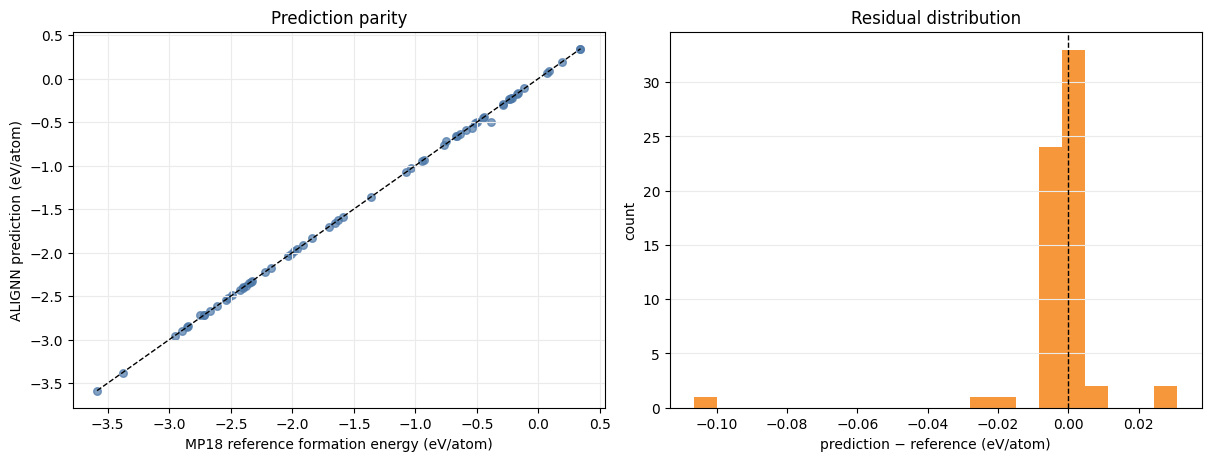

In [74]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

limits = [min(reference.min(), predicted.min()), max(reference.max(), predicted.max())]
axes[0].scatter(reference, predicted, alpha=0.7, s=30, color="#4c78a8")
axes[0].plot(limits, limits, color="black", linestyle="--", linewidth=1)
axes[0].set(
    xlabel="MP18 reference formation energy (eV/atom)",
    ylabel="ALIGNN prediction (eV/atom)",
    title="Prediction parity",
)
axes[0].grid(color="0.92")

axes[1].hist(residual, bins=min(30, max(5, len(results) // 3)), color="#f58518", alpha=0.85)
axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].set(
    xlabel="prediction − reference (eV/atom)",
    ylabel="count",
    title="Residual distribution",
)
axes[1].grid(axis="y", color="0.92")
plt.show()


## 9. Largest errors and saved predictions

Large residuals can reflect unusual chemistry, structures outside the model's effective training domain, DFT/reference issues, or ordinary model error. They should be investigated rather than automatically removed.


In [75]:
largest_errors = (
    results.assign(absolute_error_eV_atom=results["error_eV_atom"].abs())
    .sort_values("absolute_error_eV_atom", ascending=False)
    .head(15)
)
largest_errors[[
    "mp_id", "formula", "reference_e_form_eV_atom",
    "predicted_e_form_eV_atom", "error_eV_atom",
    "absolute_error_eV_atom",
]].round(5)


,mp_id,formula,reference_e_form_eV_atom,predicted_e_form_eV_atom,error_eV_atom,absolute_error_eV_atom
26,mp-570991,TiSi2,-0.38846,-0.49488,-0.10642,0.10642
22,mp-558851,Cs2KCoF6,-2.75229,-2.72130,0.03099,0.03099
15,mp-30190,UMo13P9,-0.53894,-0.56444,-0.02550,0.02550
20,mp-542003,Yb2Ni12P7,-0.74747,-0.72295,0.02452,0.02452
58,mp-981365,V2ReRu,-0.29030,-0.30619,-0.01590,0.01590
44,mp-772664,Na2CoAsCO7,-1.83833,-1.82931,0.00901,0.00901
56,mp-978252,Ce2Zn17,-0.24085,-0.23275,0.00810,0.00810
61,mvc-2260,Cr9O13,-2.03452,-2.04232,-0.00780,0.00780
11,mp-2463,LuFe2,-0.17578,-0.18132,-0.00554,0.00554
34,mp-743913,CoH14C10N8O2,-0.29183,-0.29698,-0.00515,0.00515


In [76]:
if SAVE_RESULTS:
    output_path = OUTPUT_PATH.expanduser().resolve()
    output_path.parent.mkdir(parents=True, exist_ok=True)
    results.to_csv(output_path, index=False)
    print(f"Saved {len(results):,} predictions to {output_path}")
else:
    print("SAVE_RESULTS is False; no CSV was written.")


Saved 64 predictions to /Users/jae3goals/Jupyter Code on Root/MSE420 AI Forensics/demonstrations/alignn_mp18_formation_energy_predictions.csv


## 10. ALIGNN parameter-loss landscape

This example adapts the random-plane method from [Oxford Loss Landscapes](https://github.com/TRustworthy-AI-Tools-for-Science/oxford-loss-landscapes) at commit `77b05b5b3845117abc7ad6b0df5950ecdd507826`. It is complementary to the input perturbations above: the crystal graphs and MP18 targets remain fixed while the pretrained ALIGNN parameters move along two random, approximately orthogonal, filter-normalized directions. At every grid point we measure mean squared formation-energy error on a small, fixed subset spanning the selected label range.

`LOSS_LANDSCAPE_DISTANCE = 0.02` probes an approximately ±1% neighborhood in relative model-norm units. The default even grid includes the original parameter vector exactly. This is a local stability diagnostic for this particular evaluation subset—not a reconstruction of ALIGNN's original training landscape, a causal explanation, or evidence that the selected MP18 labels are out of sample. The Oxford routine works in place, so `deepcopy_model=True` is mandatory here; an exact post-run parameter check protects the live pretrained model.


In [77]:
# Build one fixed graph batch and a graph-aware metric for repeated parameter evaluations.
landscape_count = min(LOSS_LANDSCAPE_STRUCTURE_LIMIT, len(robustness_records))
landscape_positions = np.linspace(
    0, len(robustness_records) - 1, landscape_count, dtype=int
)
landscape_records = [robustness_records[position] for position in landscape_positions]
landscape_indices = [robustness_indices[position] for position in landscape_positions]
landscape_atoms = [robustness_atoms[position] for position in landscape_positions]
landscape_prepared = [graph_inputs_from_atoms(atoms) for atoms in landscape_atoms]
landscape_graphs, landscape_line_graphs, landscape_lattices = zip(*landscape_prepared)
landscape_inputs = [
    dgl.batch(list(landscape_graphs)).to(model_device),
    dgl.batch(list(landscape_line_graphs)).to(model_device),
    torch.stack(list(landscape_lattices)).to(model_device),
]
landscape_targets = torch.as_tensor(
    [float(np.asarray(record["e_form"]).reshape(-1)[0]) for record in landscape_records],
    dtype=torch.float32, device=model_device,
)


class ALIGNNFormationEnergyMSE(Metric):
    """MSE metric compatible with Oxford Loss Landscapes and ALIGNN graph batches."""

    def __init__(self, inputs, targets):
        super().__init__()
        self.inputs = inputs
        self.targets = targets

    def __call__(self, model_wrapper):
        model_wrapper.eval()
        with torch.inference_mode():
            predictions = model_wrapper.forward(self.inputs).reshape(-1)
            return torch.mean((predictions - self.targets) ** 2).item()


landscape_wrapper = oll.SimpleModelWrapper(model)
landscape_metric = ALIGNNFormationEnergyMSE(landscape_inputs, landscape_targets)
baseline_landscape_mse = float(oll.point(landscape_wrapper, landscape_metric))
with torch.inference_mode():
    baseline_landscape_predictions = model(landscape_inputs).reshape(-1).detach().cpu().numpy()

landscape_evaluation_records = pd.DataFrame({
    "mp18_index": landscape_indices,
    "mp_id": [mp_identifier(record, index) for record, index in zip(landscape_records, landscape_indices)],
    "formula": [atoms.composition.reduced_formula for atoms in landscape_atoms],
    "reference_e_form_eV_atom": landscape_targets.detach().cpu().numpy(),
    "baseline_prediction_eV_atom": baseline_landscape_predictions,
})
landscape_evaluation_records["baseline_error_eV_atom"] = (
    landscape_evaluation_records["baseline_prediction_eV_atom"]
    - landscape_evaluation_records["reference_e_form_eV_atom"]
)
print(f"Landscape objective: {landscape_count} structures; baseline MSE = {baseline_landscape_mse:.8f} (eV/atom)^2")
landscape_evaluation_records.round(6)


Landscape objective: 12 structures; baseline MSE = 0.00002963 (eV/atom)^2


,mp18_index,mp_id,formula,reference_e_form_eV_atom,baseline_prediction_eV_atom,baseline_error_eV_atom
0,4542,mp-12647,TbNbO4,-3.584933,-3.586724,-0.001791
1,41557,mp-758393,Li3Ti2P3O12,-2.849620,-2.849034,0.000586
2,42680,mp-761956,Li3V3P8O29,-2.541298,-2.543226,-0.001929
3,36217,mp-690004,LiCoP4O12,-2.377988,-2.379539,-0.001552
4,22432,mp-554638,Ca2Ru2O7,-2.176378,-2.175847,0.000531
5,50430,mp-772664,Na2CoAsCO7,-1.838327,-1.829313,0.009013
6,13745,mp-27978,PuI3,-1.078602,-1.079470,-0.000867
7,5835,mp-15322,ScSiCu,-0.667126,-0.665840,0.001286
8,61929,mp-979423,YGa3,-0.517068,-0.514642,0.002426
9,62143,mp-981365,V2ReRu,-0.290298,-0.306194,-0.015896


In [78]:
# Compute a reproducible filter-normalized random plane around the pretrained weights.
if LOSS_LANDSCAPE_STEPS < 4 or LOSS_LANDSCAPE_STEPS % 2:
    raise ValueError("LOSS_LANDSCAPE_STEPS must be an even integer >= 4 so the grid includes zero.")
if LOSS_LANDSCAPE_DISTANCE <= 0:
    raise ValueError("LOSS_LANDSCAPE_DISTANCE must be positive.")

torch.manual_seed(LOSS_LANDSCAPE_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(LOSS_LANDSCAPE_SEED)
parameter_snapshot = [parameter.detach().clone() for parameter in model.parameters()]

loss_landscape_mse = oll.random_plane(
    landscape_wrapper,
    metric=landscape_metric,
    distance=LOSS_LANDSCAPE_DISTANCE,
    steps=LOSS_LANDSCAPE_STEPS,
    normalization=LOSS_LANDSCAPE_NORMALIZATION,
    deepcopy_model=True,
)

model_parameters_unchanged = all(
    torch.equal(before, after.detach())
    for before, after in zip(parameter_snapshot, model.parameters())
)
if not model_parameters_unchanged:
    raise RuntimeError("Oxford landscape evaluation altered the live ALIGNN parameters.")

# These coordinates reproduce the sampling convention in Oxford random_plane.
landscape_axis = (
    -LOSS_LANDSCAPE_DISTANCE / 2
    + np.arange(LOSS_LANDSCAPE_STEPS) * LOSS_LANDSCAPE_DISTANCE / LOSS_LANDSCAPE_STEPS
)
alpha_grid, beta_grid = np.meshgrid(landscape_axis, landscape_axis, indexing="ij")
loss_landscape_rmse = np.sqrt(np.maximum(loss_landscape_mse, 0.0))
loss_landscape_results = pd.DataFrame({
    "alpha_relative_model_norm": alpha_grid.ravel(),
    "beta_relative_model_norm": beta_grid.ravel(),
    "mse_eV2_atom2": loss_landscape_mse.ravel(),
    "rmse_eV_atom": loss_landscape_rmse.ravel(),
})
loss_landscape_results["delta_mse_from_pretrained_eV2_atom2"] = (
    loss_landscape_results["mse_eV2_atom2"] - baseline_landscape_mse
)
loss_landscape_results["mse_ratio_to_pretrained"] = (
    loss_landscape_results["mse_eV2_atom2"] / baseline_landscape_mse
    if baseline_landscape_mse > 0 else np.nan
)

zero_index = int(np.argmin(np.abs(landscape_axis)))
sampled_pretrained_mse = float(loss_landscape_mse[zero_index, zero_index])
# Allow float32 roundoff from Oxford's in-place traversal back to the plane origin.
if not np.isclose(sampled_pretrained_mse, baseline_landscape_mse, rtol=1e-4, atol=1e-8):
    raise RuntimeError("The zero-coordinate grid value does not reproduce the pretrained loss.")
print(f"Computed {loss_landscape_mse.size} parameter points; live ALIGNN unchanged: {model_parameters_unchanged}")
loss_landscape_results.head().round(8)


Calculating Surface...: 100%|██████████| 10/10 [00:30<00:00,  3.00s/it]

Computed 100 parameter points; live ALIGNN unchanged: True


,alpha_relative_model_norm,beta_relative_model_norm,mse_eV2_atom2,rmse_eV_atom,delta_mse_from_pretrained_eV2_atom2,mse_ratio_to_pretrained
0,-0.01,-0.010,0.000021,0.004621,-0.000008,0.720550
1,-0.01,-0.008,0.000022,0.004661,-0.000008,0.733246
2,-0.01,-0.006,0.000023,0.004747,-0.000007,0.760570
3,-0.01,-0.004,0.000024,0.004879,-0.000006,0.803450
4,-0.01,-0.002,0.000026,0.005056,-0.000004,0.862808


In [79]:
# Quantify local sharpness and save the full grid for later figures.
axis_step = LOSS_LANDSCAPE_DISTANCE / LOSS_LANDSCAPE_STEPS
curvature_alpha = (
    loss_landscape_mse[zero_index + 1, zero_index]
    - 2 * loss_landscape_mse[zero_index, zero_index]
    + loss_landscape_mse[zero_index - 1, zero_index]
) / axis_step**2
curvature_beta = (
    loss_landscape_mse[zero_index, zero_index + 1]
    - 2 * loss_landscape_mse[zero_index, zero_index]
    + loss_landscape_mse[zero_index, zero_index - 1]
) / axis_step**2
minimum_location = np.unravel_index(np.argmin(loss_landscape_mse), loss_landscape_mse.shape)
baseline_landscape_rmse = float(np.sqrt(max(baseline_landscape_mse, 0.0)))

loss_landscape_summary = {
    "structures": int(landscape_count),
    "grid_points": int(loss_landscape_mse.size),
    "baseline_mse_eV2_atom2": baseline_landscape_mse,
    "baseline_rmse_eV_atom": baseline_landscape_rmse,
    "minimum_mse_eV2_atom2": float(loss_landscape_mse.min()),
    "minimum_alpha_relative_model_norm": float(landscape_axis[minimum_location[0]]),
    "minimum_beta_relative_model_norm": float(landscape_axis[minimum_location[1]]),
    "maximum_mse_eV2_atom2": float(loss_landscape_mse.max()),
    "maximum_rmse_increase_eV_atom": float(loss_landscape_rmse.max() - baseline_landscape_rmse),
    "fraction_within_one_published_mae_of_baseline_rmse": float(np.mean(
        loss_landscape_rmse <= baseline_landscape_rmse + PUBLISHED_MP18_MAE_EV_ATOM
    )),
    "finite_difference_curvature_alpha": float(curvature_alpha),
    "finite_difference_curvature_beta": float(curvature_beta),
    "live_model_parameters_unchanged": bool(model_parameters_unchanged),
}

loss_landscape_manifest = {
    "repository": "https://github.com/TRustworthy-AI-Tools-for-Science/oxford-loss-landscapes",
    "repository_commit": "77b05b5b3845117abc7ad6b0df5950ecdd507826",
    "package_version": version("oxford-loss-landscapes"),
    "model": MODEL_NAME,
    "metric": "mean squared formation-energy error in (eV/atom)^2",
    "normalization": LOSS_LANDSCAPE_NORMALIZATION,
    "distance": LOSS_LANDSCAPE_DISTANCE,
    "steps": LOSS_LANDSCAPE_STEPS,
    "seed": LOSS_LANDSCAPE_SEED,
    "mp18_indices": [int(index) for index in landscape_indices],
    "coordinate_convention": "-distance/2 + index*distance/steps; zero is the pretrained model",
    "summary": loss_landscape_summary,
}
if SAVE_RESULTS:
    ROBUSTNESS_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    loss_landscape_results.to_csv(ROBUSTNESS_OUTPUT_DIR / "parameter_loss_landscape.csv", index=False)
    landscape_evaluation_records.to_csv(
        ROBUSTNESS_OUTPUT_DIR / "parameter_loss_landscape_records.csv", index=False
    )
    (ROBUSTNESS_OUTPUT_DIR / "parameter_loss_landscape_manifest.json").write_text(
        json.dumps(loss_landscape_manifest, indent=2) + "\n"
    )
pd.Series(loss_landscape_summary, name="ALIGNN parameter landscape").to_frame().round(8)


,ALIGNN parameter landscape
structures,12
grid_points,100
baseline_mse_eV2_atom2,0.00003
baseline_rmse_eV_atom,0.005444
minimum_mse_eV2_atom2,0.000021
minimum_alpha_relative_model_norm,-0.008
minimum_beta_relative_model_norm,-0.01
maximum_mse_eV2_atom2,0.00005
maximum_rmse_increase_eV_atom,0.001641
fraction_within_one_published_mae_of_baseline_rmse,1.0


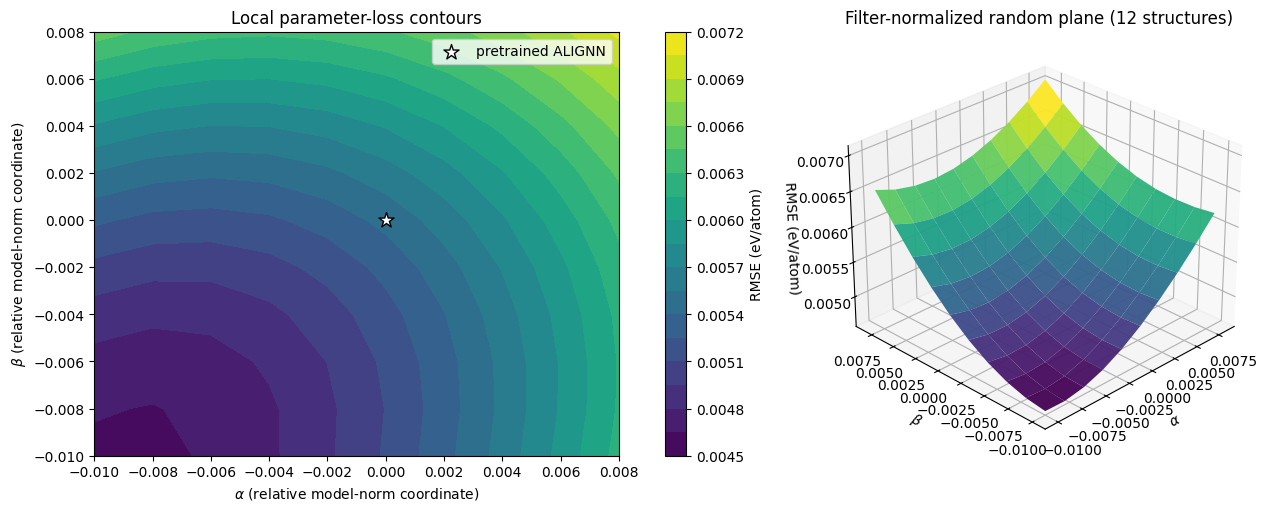

In [80]:
figure = plt.figure(figsize=(13, 5), constrained_layout=True)
contour_axis = figure.add_subplot(1, 2, 1)
surface_axis = figure.add_subplot(1, 2, 2, projection="3d")

contours = contour_axis.contourf(
    alpha_grid, beta_grid, loss_landscape_rmse, levels=20, cmap="viridis"
)
contour_axis.scatter(0, 0, marker="*", s=130, color="white", edgecolor="black", label="pretrained ALIGNN")
contour_axis.set(
    xlabel=r"$\alpha$ (relative model-norm coordinate)",
    ylabel=r"$\beta$ (relative model-norm coordinate)",
    title="Local parameter-loss contours",
)
contour_axis.legend(loc="best")
figure.colorbar(contours, ax=contour_axis, label="RMSE (eV/atom)")

surface_axis.plot_surface(
    alpha_grid, beta_grid, loss_landscape_rmse, cmap="viridis",
    edgecolor="none", antialiased=True, alpha=0.95,
)
surface_axis.set(
    xlabel=r"$\alpha$", ylabel=r"$\beta$", zlabel="RMSE (eV/atom)",
    title=f"Filter-normalized random plane ({landscape_count} structures)",
)
surface_axis.view_init(elev=28, azim=-135)
if SAVE_RESULTS:
    figure.savefig(ROBUSTNESS_OUTPUT_DIR / "parameter_loss_landscape.png", dpi=180, bbox_inches="tight")
plt.show()


## 11. MP21-only alloys of interest: robustness and stability shift

Li *et al.* define **alloys of interest (AoI)** as compounds containing only one or more of 34 metallic elements. Their exact Materials Project snapshot (2021-11-10) contains 7,800 AoI. The authors' MP18-to-MP21 crosswalk identifies 2,261 structures already represented in MP18; this section excludes those and evaluates the remaining **5,539 MP21-only AoI**. These are the paper's database-era out-of-distribution test compounds—not an ALIGNN validation split.

The data come from the authors' [code repository](https://github.com/mathsphy/paper-ml-robustness-material-property) and [archived Zenodo record](https://zenodo.org/records/7659267). The 151.9 MB archive is downloaded once to `~/.cache/mse420-ai-forensics/li_2023_aoi/data.zip`, checksum-verified, and reused on later runs. Set `LOCAL_AOI_DATA_ZIP` if the archive is stored elsewhere. It is read directly without extraction and is not copied into this Git repository.

Three comparisons make the change visible:

1. the authors' saved predictions quantify baseline generalization over all 5,539 MP21-only AoI;
2. 32 formation-energy-stratified MP21-only structures receive the same coordinate-noise and lattice-strain perturbations used above; and
3. 12 MP21-only structures receive the same Oxford parameter plane as 12 MP18 reference structures—the same seed, directions, normalization, width, and grid.

The energy-stratified subset deliberately spans the full target range rather than estimating a population average. All selected IDs, observables, perturbation results, landscape grids, and comparison summaries are saved for later figures.

In [81]:
AOI_ELEMENTS = frozenset(
    "Li Be Na Mg Al K Ca Sc Ti V Cr Mn Fe Co Ni Cu Zn Ga "
    "Rb Sr Y Zr Nb Mo Tc Ru Rh Pd Ag Cd In Sn Cs Ba".split()
)
if len(AOI_ELEMENTS) != 34:
    raise RuntimeError(f"Expected 34 AoI elements, received {len(AOI_ELEMENTS)}.")


def md5sum(path, chunk_size=1024 * 1024):
    digest = hashlib.md5()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def cached_aoi_archive():
    """Download the authors' immutable archive once, then reuse it."""
    if LOCAL_AOI_DATA_ZIP is not None:
        archive = Path(LOCAL_AOI_DATA_ZIP).expanduser().resolve()
    else:
        AOI_DATA_CACHE_DIR.mkdir(parents=True, exist_ok=True)
        archive = AOI_DATA_CACHE_DIR / "data.zip"
        if not archive.exists():
            partial = archive.with_suffix(".zip.part")
            with requests.get(AOI_DATA_URL, stream=True, timeout=(15, 180)) as response:
                response.raise_for_status()
                total = int(response.headers.get("content-length", 0)) or None
                with partial.open("wb") as handle, tqdm(
                    total=total, unit="B", unit_scale=True, desc="Downloading Li et al. MP21 data"
                ) as progress:
                    for chunk in response.iter_content(chunk_size=1024 * 1024):
                        if chunk:
                            handle.write(chunk)
                            progress.update(len(chunk))
            partial.replace(archive)

    if not archive.exists():
        raise FileNotFoundError(f"AoI archive was not found: {archive}")
    observed_size = archive.stat().st_size
    observed_md5 = md5sum(archive)
    if observed_size != AOI_DATA_ARCHIVE_SIZE or observed_md5 != AOI_DATA_ARCHIVE_MD5:
        raise RuntimeError(
            "AoI archive integrity check failed: "
            f"size={observed_size}, md5={observed_md5}. "
            "Remove or replace the archive before continuing."
        )
    return archive


def mp21_structure_to_atoms(serialized_structure):
    """Convert the archived pymatgen dictionary to JARVIS Atoms without pymatgen."""
    structure = ast.literal_eval(serialized_structure)
    coordinates, elements = [], []
    for site in structure["sites"]:
        species = site["species"]
        if len(species) != 1 or not np.isclose(float(species[0]["occu"]), 1.0):
            raise ValueError("The selected structure contains partial/disordered occupancy.")
        elements.append(species[0]["element"])
        coordinates.append(site["abc"])
    return Atoms(
        lattice_mat=structure["lattice"]["matrix"],
        coords=coordinates,
        elements=elements,
        cartesian=False,
    )


aoi_archive = cached_aoi_archive()
with zipfile.ZipFile(aoi_archive) as archive:
    mp21_aoi = pd.read_csv(
        archive.open("data/MP_alloys_2021.11.10_273feat.csv"),
        usecols=[
            "material_id", "formula_pretty", "formation_energy_per_atom", "elements",
            "task_ids", "space_group_number", "structure_as_dict",
        ],
    )
    mp18_mp21_crosswalk = pd.read_csv(
        archive.open("data/megnet_updated_id_MP21.csv"), usecols=["id_MP18", "id_MP21"]
    )
    authors_alignn_predictions = pd.read_csv(
        archive.open("data/mp_e_form_alignnn_MP21_alloys.csv")
    )

mp18_represented_mp21_ids = frozenset(mp18_mp21_crosswalk["id_MP21"].dropna().astype(str))
mp21_aoi["represented_in_mp18"] = mp21_aoi["material_id"].isin(mp18_represented_mp21_ids)
mp21_only_aoi = mp21_aoi.loc[~mp21_aoi["represented_in_mp18"]].copy()
mp21_only_aoi = mp21_only_aoi.merge(
    authors_alignn_predictions, on="material_id", how="left", validate="one_to_one"
)

expected_counts = {"MP21 AoI": 7800, "MP18 overlap": 2261, "MP21-only AoI": 5539}
observed_counts = {
    "MP21 AoI": len(mp21_aoi),
    "MP18 overlap": int(mp21_aoi["represented_in_mp18"].sum()),
    "MP21-only AoI": len(mp21_only_aoi),
}
if observed_counts != expected_counts:
    raise RuntimeError(f"Unexpected AoI split: {observed_counts}; expected {expected_counts}.")
if mp21_only_aoi["Ef_alignn"].isna().any():
    raise RuntimeError("The authors' ALIGNN predictions do not cover every MP21-only AoI.")

mp21_only_aoi["authors_error_eV_atom"] = (
    mp21_only_aoi["Ef_alignn"] - mp21_only_aoi["formation_energy_per_atom"]
)
mp21_only_full_metrics = {
    "structures": int(len(mp21_only_aoi)),
    "MAE_eV_atom": float(mp21_only_aoi["authors_error_eV_atom"].abs().mean()),
    "RMSE_eV_atom": float(np.sqrt(np.mean(mp21_only_aoi["authors_error_eV_atom"] ** 2))),
    "median_absolute_error_eV_atom": float(mp21_only_aoi["authors_error_eV_atom"].abs().median()),
    "paper_reported_ALIGNN_MAE_eV_atom": 0.297,
}

# Select evenly spaced target-energy ranks so the robustness case study covers the domain.
aoi_selection_count = min(AOI_MP21_ROBUSTNESS_LIMIT, len(mp21_only_aoi))
aoi_energy_order = np.argsort(mp21_only_aoi["formation_energy_per_atom"].to_numpy())
aoi_selection_positions = aoi_energy_order[
    np.linspace(0, len(aoi_energy_order) - 1, aoi_selection_count, dtype=int)
]
aoi_selected = mp21_only_aoi.iloc[aoi_selection_positions].reset_index().rename(
    columns={"index": "mp21_table_row"}
)
aoi_atoms = [mp21_structure_to_atoms(value) for value in aoi_selected["structure_as_dict"]]
aoi_records = [
    {
        "id": row.material_id,
        "atoms": atoms.to_dict(),
        "e_form": float(row.formation_energy_per_atom),
    }
    for row, atoms in zip(aoi_selected.itertuples(index=False), aoi_atoms)
]
aoi_indices = aoi_selected["mp21_table_row"].astype(int).tolist()
aoi_baselines = evaluate_atom_structures(aoi_atoms)

aoi_baseline_results = pd.DataFrame([{
    "mp21_table_row": int(row.mp21_table_row),
    "material_id": row.material_id,
    "formula": row.formula_pretty,
    "space_group_number": int(row.space_group_number),
    "reference_e_form_eV_atom": float(row.formation_energy_per_atom),
    "authors_saved_prediction_eV_atom": float(row.Ef_alignn),
    "current_model_prediction_eV_atom": baseline["prediction_eV_atom"],
    "current_model_error_eV_atom": baseline["prediction_eV_atom"] - float(row.formation_energy_per_atom),
    "current_minus_authors_prediction_eV_atom": baseline["prediction_eV_atom"] - float(row.Ef_alignn),
    "graph_nodes": baseline["graph_nodes"],
    "graph_edges": baseline["graph_edges"],
    "minimum_periodic_distance_angstrom": baseline["min_periodic_distance_angstrom"],
} for row, baseline in zip(aoi_selected.itertuples(index=False), aoi_baselines)])

aoi_catalog = mp21_only_aoi.drop(columns=["structure_as_dict"]).copy()
if SAVE_RESULTS:
    ROBUSTNESS_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    aoi_catalog.to_csv(ROBUSTNESS_OUTPUT_DIR / "mp21_only_aoi_catalog.csv", index=False)
    aoi_baseline_results.to_csv(
        ROBUSTNESS_OUTPUT_DIR / "mp21_only_aoi_selected_baselines.csv", index=False
    )

print(f"AoI archive: {aoi_archive}")
print(f"Verified split: {observed_counts}")
display(pd.Series(mp21_only_full_metrics, name="MP21-only AoI (authors' saved ALIGNN predictions)").to_frame())
aoi_baseline_results.round(6)

AoI archive: /Users/jae3goals/.cache/mse420-ai-forensics/li_2023_aoi/data.zip
Verified split: {'MP21 AoI': 7800, 'MP18 overlap': 2261, 'MP21-only AoI': 5539}


,MP21-only AoI (authors' saved ALIGNN predictions)
structures,5539.000000
MAE_eV_atom,0.296562
RMSE_eV_atom,0.746539
median_absolute_error_eV_atom,0.032476
paper_reported_ALIGNN_MAE_eV_atom,0.297000


,mp21_table_row,material_id,formula,space_group_number,reference_e_form_eV_atom,authors_saved_prediction_eV_atom,current_model_prediction_eV_atom,current_model_error_eV_atom,current_minus_authors_prediction_eV_atom,graph_nodes,graph_edges,minimum_periodic_distance_angstrom
0,4463,mp-1186951,Sc2PdRh,225,-0.953069,-0.980139,-0.979827,-0.026757,0.000312,4,56,2.837143
1,2456,mp-1064367,BaPd,194,-0.539302,-0.573470,-0.573829,-0.034527,-0.000359,4,56,2.825440
2,4047,mp-1203938,Y2Ni7Sn3,64,-0.423892,-0.428925,-0.427679,-0.003787,0.001246,48,604,2.396675
3,4761,mp-1208517,Ti5FeSn3,193,-0.356732,-0.298981,-0.287380,0.069353,0.011601,18,244,2.415845
4,511,mp-1215020,Al2(Zn13Pd3)3,216,-0.301921,-0.234871,-0.228628,0.073293,0.006243,100,1304,2.551341
5,678,mp-1227419,Ca(MnAl3)3,12,-0.254769,-0.263749,-0.262079,-0.007311,0.001670,13,164,2.525210
6,5013,mp-1087476,K2Mg5Sn3,139,-0.202627,-0.235226,-0.222532,-0.019905,0.012693,10,140,2.910766
7,1714,mp-1215320,ZrCrCo,38,-0.159715,-0.201132,-0.201717,-0.042002,-0.000585,12,146,2.441740
8,3445,mp-1094801,MgSn,123,-0.119237,-0.132106,-0.110884,0.008353,0.021221,2,32,3.206836
9,1369,mp-1094629,MgGa2,189,-0.078479,-0.104236,-0.103985,-0.025506,0.000252,6,72,3.000116


In [82]:
# Apply the same coordinate-noise directions/magnitudes and all eight strain modes as MP18.
aoi_robustness_rows = []
aoi_coordinate_jobs = []
for record, dataset_index, atoms, baseline in zip(aoi_records, aoi_indices, aoi_atoms, aoi_baselines):
    lattice = np.asarray(atoms.lattice_mat)
    common = {
        "evaluation_domain": "MP21-only AoI",
        "source_snapshot": "Materials Project 2021-11-10",
        "mp18_index": np.nan,
        "mp21_table_row": int(dataset_index),
    }
    for replicate in range(ATOMIC_DISPLACEMENT_DIRECTIONS):
        seed = int(np.random.SeedSequence(
            [RANDOM_SEED, 300_000, dataset_index, replicate]
        ).generate_state(1)[0])
        aoi_robustness_rows.append(perturbation_row(
            record, dataset_index, baseline, baseline,
            family="coordinate_noise", perturbation_type="cartesian_displacement",
            magnitude=0.0, signed_magnitude=0.0, magnitude_unit="angstrom_rms",
            replicate=replicate, seed=seed, direction_id=f"gaussian_{replicate}",
            extra={**common, "displacement_definition": "baseline; no displacement"},
        ))
        rng = np.random.default_rng(seed)
        direction = rng.normal(size=(atoms.num_atoms, 3))
        direction -= direction.mean(axis=0, keepdims=True)
        direction_rms = float(np.sqrt(np.mean(np.sum(direction**2, axis=1))))
        if direction_rms < 1e-12:
            for magnitude in ATOMIC_DISPLACEMENT_MAGNITUDES_ANGSTROM:
                aoi_robustness_rows.append(perturbation_row(
                    record, dataset_index, baseline, None,
                    family="coordinate_noise", perturbation_type="cartesian_displacement",
                    magnitude=magnitude, signed_magnitude=magnitude, magnitude_unit="angstrom_rms",
                    replicate=replicate, seed=seed, direction_id=f"gaussian_{replicate}",
                    status="not_applicable_zero_internal_degrees_of_freedom", extra=common,
                ))
            continue
        direction /= direction_rms
        for magnitude in ATOMIC_DISPLACEMENT_MAGNITUDES_ANGSTROM:
            displacement = float(magnitude) * direction
            displaced_fractional = (
                np.asarray(atoms.cart_coords) + displacement
            ) @ np.linalg.inv(lattice)
            aoi_coordinate_jobs.append({
                "record": record, "dataset_index": dataset_index, "baseline": baseline,
                "atoms": make_fractional_atoms(lattice, displaced_fractional, atoms.elements),
                "magnitude": float(magnitude), "replicate": replicate, "seed": seed,
                "direction_id": f"gaussian_{replicate}",
                "extra": {
                    **common,
                    "displacement_definition": "zero-centroid Gaussian Cartesian direction normalized to RMS=1",
                    "requested_rms_displacement_angstrom": float(magnitude),
                    "realized_rms_displacement_angstrom": float(np.sqrt(np.mean(np.sum(displacement**2, axis=1)))),
                    "maximum_displacement_angstrom": float(np.linalg.norm(displacement, axis=1).max()),
                    "net_displacement_angstrom": float(np.linalg.norm(displacement.sum(axis=0))),
                },
            })

aoi_coordinate_evaluations = evaluate_atom_structures([job["atoms"] for job in aoi_coordinate_jobs])
for job, perturbed in zip(aoi_coordinate_jobs, aoi_coordinate_evaluations):
    aoi_robustness_rows.append(perturbation_row(
        job["record"], job["dataset_index"], job["baseline"], perturbed,
        family="coordinate_noise", perturbation_type="cartesian_displacement",
        magnitude=job["magnitude"], signed_magnitude=job["magnitude"],
        magnitude_unit="angstrom_rms", replicate=job["replicate"], seed=job["seed"],
        direction_id=job["direction_id"], topology_comparable=True, extra=job["extra"],
    ))

aoi_strain_jobs = []
for record, dataset_index, atoms, baseline in zip(aoi_records, aoi_indices, aoi_atoms, aoi_baselines):
    lattice = np.asarray(atoms.lattice_mat)
    fractional = np.asarray(atoms.frac_coords)
    common = {
        "evaluation_domain": "MP21-only AoI",
        "source_snapshot": "Materials Project 2021-11-10",
        "mp18_index": np.nan,
        "mp21_table_row": int(dataset_index),
    }
    for strain_mode, unit_tensor in strain_directions.items():
        aoi_robustness_rows.append(perturbation_row(
            record, dataset_index, baseline, baseline,
            family="lattice_strain", perturbation_type=strain_mode,
            magnitude=0.0, signed_magnitude=0.0, magnitude_unit="strain_fraction",
            direction_id=strain_mode,
            extra={
                **common, "strain_definition": "baseline; identity deformation",
                "strain_xx": 0.0, "strain_yy": 0.0, "strain_zz": 0.0,
                "strain_xy": 0.0, "strain_xz": 0.0, "strain_yz": 0.0,
                "strain_trace": 0.0, "strain_frobenius_norm": 0.0,
                "deformation_determinant": 1.0,
            },
        ))
        for magnitude in STRAIN_MAGNITUDES:
            for sign in (-1.0, 1.0):
                signed_magnitude = sign * float(magnitude)
                strain_tensor = signed_magnitude * unit_tensor
                deformation = np.eye(3) + strain_tensor
                aoi_strain_jobs.append({
                    "record": record, "dataset_index": dataset_index, "baseline": baseline,
                    "atoms": make_fractional_atoms(
                        lattice @ deformation.T, fractional, atoms.elements
                    ),
                    "strain_mode": strain_mode, "magnitude": float(magnitude),
                    "signed_magnitude": signed_magnitude,
                    "extra": {
                        **common,
                        "strain_definition": "symmetric small-strain tensor; fractional coordinates fixed",
                        "strain_xx": strain_tensor[0, 0], "strain_yy": strain_tensor[1, 1],
                        "strain_zz": strain_tensor[2, 2], "strain_xy": strain_tensor[0, 1],
                        "strain_xz": strain_tensor[0, 2], "strain_yz": strain_tensor[1, 2],
                        "strain_trace": float(np.trace(strain_tensor)),
                        "strain_frobenius_norm": float(np.linalg.norm(strain_tensor)),
                        "deformation_determinant": float(np.linalg.det(deformation)),
                    },
                })

aoi_strain_evaluations = evaluate_atom_structures([job["atoms"] for job in aoi_strain_jobs])
for job, perturbed in zip(aoi_strain_jobs, aoi_strain_evaluations):
    aoi_robustness_rows.append(perturbation_row(
        job["record"], job["dataset_index"], job["baseline"], perturbed,
        family="lattice_strain", perturbation_type=job["strain_mode"],
        magnitude=job["magnitude"], signed_magnitude=job["signed_magnitude"],
        magnitude_unit="strain_fraction", direction_id=job["strain_mode"],
        topology_comparable=True, extra=job["extra"],
    ))

aoi_input_robustness_results = pd.DataFrame(aoi_robustness_rows).sort_values(
    ["perturbation_family", "perturbation_type", "magnitude", "mp21_table_row", "replicate"]
)
mp18_reference_input_results = pd.concat(
    [coordinate_noise_results, lattice_strain_results], ignore_index=True, sort=False
)
mp18_reference_input_results["evaluation_domain"] = "MP18 reference subset"
input_robustness_comparison = pd.concat(
    [mp18_reference_input_results, aoi_input_robustness_results],
    ignore_index=True, sort=False,
)
input_robustness_summary = input_robustness_comparison.groupby(
    ["evaluation_domain", "perturbation_family", "perturbation_type", "magnitude"],
    dropna=False,
).agg(
    samples=("absolute_delta_prediction_eV_atom", "count"),
    median_abs_delta_eV_atom=("absolute_delta_prediction_eV_atom", "median"),
    p95_abs_delta_eV_atom=("absolute_delta_prediction_eV_atom", lambda values: values.quantile(0.95)),
    maximum_abs_delta_eV_atom=("absolute_delta_prediction_eV_atom", "max"),
    topology_change_rate=("topology_changed", "mean"),
    structural_valid_rate=("structural_valid", "mean"),
).reset_index()

# One concise table at the largest perturbation magnitude for every perturbation type.
robustness_change_at_max = (
    input_robustness_summary.sort_values("magnitude")
    .groupby(["evaluation_domain", "perturbation_family", "perturbation_type"], as_index=False)
    .tail(1)
    .pivot(
        index=["perturbation_family", "perturbation_type", "magnitude"],
        columns="evaluation_domain",
        values=["median_abs_delta_eV_atom", "p95_abs_delta_eV_atom", "topology_change_rate"],
    )
)

if SAVE_RESULTS:
    aoi_input_robustness_results.to_csv(
        ROBUSTNESS_OUTPUT_DIR / "mp21_only_aoi_input_robustness.csv", index=False
    )
    input_robustness_summary.to_csv(
        ROBUSTNESS_OUTPUT_DIR / "mp18_vs_mp21_only_aoi_input_robustness_summary.csv", index=False
    )
robustness_change_at_max.round(8)

median_abs_delta_eV_atom  \
evaluation_domain                                       MP18 reference subset   
perturbation_family perturbation_type      magnitude                            
coordinate_noise    cartesian_displacement 0.10                      0.031198   
lattice_strain      isotropic              0.02                      0.020188   
                    orthorhombic_ab        0.02                      0.003926   
                    shear_ab               0.02                      0.001476   
                    shear_ac               0.02                      0.001678   
                    shear_bc               0.02                      0.000850   
                    uniaxial_a             0.02                      0.005138   
                    uniaxial_b             0.02                      0.005930   
                    uniaxial_c             0.02                      0.006328   

                                                                    \
evaluation_domain                                    MP21-only AoI   
perturbation_family perturbation_type      magnitude                 
coordinate_noise    cartesian_displacement 0.10           0.009190   
lattice_strain      isotropic              0.02           0.012322   
                    orthorhombic_ab        0.02           0.004306   
                    shear_ab               0.02           0.001239   
                    shear_ac               0.02           0.000900   
                    shear_bc               0.02           0.001012   
                    uniaxial_a             0.02           0.004646   
                    uniaxial_b             0.02           0.003912   
                    uniaxial_c             0.02           0.003615   

                                                     p95_abs_delta_eV_atom  \
evaluation_domain                                    MP18 reference subset   
perturbation_family perturbation_type      magnitude                         
coordinate_noise    cartesian_displacement 0.10                   0.075645   
lattice_strain      isotropic              0.02                   0.039310   
                    orthorhombic_ab        0.02                   0.014715   
                    shear_ab               0.02                   0.003929   
                    shear_ac               0.02                   0.006508   
                    shear_bc               0.02                   0.005065   
                    uniaxial_a             0.02                   0.022935   
                    uniaxial_b             0.02                   0.014303   
                    uniaxial_c             0.02                   0.026860   

                                                                    \
evaluation_domain                                    MP21-only AoI   
perturbation_family perturbation_type      magnitude                 
coordinate_noise    cartesian_displacement 0.10           0.038067   
lattice_strain      isotropic              0.02           0.032552   
                    orthorhombic_ab        0.02           0.036001   
                    shear_ab               0.02           0.012716   
                    shear_ac               0.02           0.026279   
                    shear_bc               0.02           0.018901   
                    uniaxial_a             0.02           0.032541   
                    uniaxial_b             0.02           0.016250   
                    uniaxial_c             0.02           0.020337   

                                                      topology_change_rate  \
evaluation_domain                                    MP18 reference subset   
perturbation_family perturbation_type      magnitude                         
coordinate_noise    cartesian_displacement 0.10                   0.900000   
lattice_strain      isotropic              0.02                   0.333333   
                    orthorhombic_ab        0.02                   0.750

In [83]:
# Compare the same Oxford random parameter plane on equal-sized MP18 and MP21-only subsets.
if AOI_PARAMETER_LANDSCAPE_STEPS < 4 or AOI_PARAMETER_LANDSCAPE_STEPS % 2:
    raise ValueError("AOI_PARAMETER_LANDSCAPE_STEPS must be an even integer >= 4.")
if AOI_PARAMETER_LANDSCAPE_STEPS != LOSS_LANDSCAPE_STEPS:
    raise ValueError("Use the same landscape grid for a direct domain comparison.")
if AOI_PARAMETER_LANDSCAPE_SEED != LOSS_LANDSCAPE_SEED:
    raise ValueError("Use the same random-plane seed for a direct domain comparison.")

aoi_landscape_count = min(AOI_MP21_PARAMETER_LANDSCAPE_LIMIT, len(aoi_records))
if aoi_landscape_count != landscape_count:
    raise RuntimeError("MP18 and MP21-only parameter landscapes must use equal sample counts.")
aoi_landscape_positions = np.linspace(0, len(aoi_records) - 1, aoi_landscape_count, dtype=int)
aoi_landscape_records = [aoi_records[position] for position in aoi_landscape_positions]
aoi_landscape_indices = [aoi_indices[position] for position in aoi_landscape_positions]
aoi_landscape_atoms = [aoi_atoms[position] for position in aoi_landscape_positions]
aoi_landscape_prepared = [graph_inputs_from_atoms(atoms) for atoms in aoi_landscape_atoms]
aoi_landscape_graphs, aoi_landscape_line_graphs, aoi_landscape_lattices = zip(*aoi_landscape_prepared)
aoi_landscape_inputs = [
    dgl.batch(list(aoi_landscape_graphs)).to(model_device),
    dgl.batch(list(aoi_landscape_line_graphs)).to(model_device),
    torch.stack(list(aoi_landscape_lattices)).to(model_device),
]
aoi_landscape_targets = torch.as_tensor(
    [float(np.asarray(record["e_form"]).reshape(-1)[0]) for record in aoi_landscape_records],
    dtype=torch.float32, device=model_device,
)
aoi_landscape_wrapper = oll.SimpleModelWrapper(model)
aoi_landscape_metric = ALIGNNFormationEnergyMSE(aoi_landscape_inputs, aoi_landscape_targets)
aoi_landscape_baseline_mse = float(oll.point(aoi_landscape_wrapper, aoi_landscape_metric))

torch.manual_seed(AOI_PARAMETER_LANDSCAPE_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(AOI_PARAMETER_LANDSCAPE_SEED)
aoi_parameter_snapshot = [parameter.detach().clone() for parameter in model.parameters()]
aoi_loss_landscape_mse = oll.random_plane(
    aoi_landscape_wrapper, metric=aoi_landscape_metric,
    distance=LOSS_LANDSCAPE_DISTANCE, steps=AOI_PARAMETER_LANDSCAPE_STEPS,
    normalization=LOSS_LANDSCAPE_NORMALIZATION, deepcopy_model=True,
)
aoi_model_parameters_unchanged = all(
    torch.equal(before, after.detach())
    for before, after in zip(aoi_parameter_snapshot, model.parameters())
)
if not aoi_model_parameters_unchanged:
    raise RuntimeError("The MP21-only landscape evaluation altered the live ALIGNN parameters.")

aoi_landscape_axis = (
    -LOSS_LANDSCAPE_DISTANCE / 2
    + np.arange(AOI_PARAMETER_LANDSCAPE_STEPS)
    * LOSS_LANDSCAPE_DISTANCE / AOI_PARAMETER_LANDSCAPE_STEPS
)
aoi_alpha_grid, aoi_beta_grid = np.meshgrid(
    aoi_landscape_axis, aoi_landscape_axis, indexing="ij"
)
aoi_loss_landscape_rmse = np.sqrt(np.maximum(aoi_loss_landscape_mse, 0.0))
aoi_zero_index = int(np.argmin(np.abs(aoi_landscape_axis)))
aoi_sampled_baseline_mse = float(aoi_loss_landscape_mse[aoi_zero_index, aoi_zero_index])
# Allow float32 roundoff from Oxford's in-place traversal back to the plane origin.
if not np.isclose(aoi_sampled_baseline_mse, aoi_landscape_baseline_mse, rtol=1e-4, atol=1e-8):
    raise RuntimeError("The MP21-only zero-coordinate grid value does not reproduce the pretrained loss.")

aoi_loss_landscape_results = pd.DataFrame({
    "alpha_relative_model_norm": aoi_alpha_grid.ravel(),
    "beta_relative_model_norm": aoi_beta_grid.ravel(),
    "mse_eV2_atom2": aoi_loss_landscape_mse.ravel(),
    "rmse_eV_atom": aoi_loss_landscape_rmse.ravel(),
})
aoi_loss_landscape_results["delta_mse_from_pretrained_eV2_atom2"] = (
    aoi_loss_landscape_results["mse_eV2_atom2"] - aoi_landscape_baseline_mse
)
aoi_axis_step = LOSS_LANDSCAPE_DISTANCE / AOI_PARAMETER_LANDSCAPE_STEPS
aoi_curvature_alpha = (
    aoi_loss_landscape_mse[aoi_zero_index + 1, aoi_zero_index]
    - 2 * aoi_loss_landscape_mse[aoi_zero_index, aoi_zero_index]
    + aoi_loss_landscape_mse[aoi_zero_index - 1, aoi_zero_index]
) / aoi_axis_step**2
aoi_curvature_beta = (
    aoi_loss_landscape_mse[aoi_zero_index, aoi_zero_index + 1]
    - 2 * aoi_loss_landscape_mse[aoi_zero_index, aoi_zero_index]
    + aoi_loss_landscape_mse[aoi_zero_index, aoi_zero_index - 1]
) / aoi_axis_step**2
aoi_baseline_rmse = float(np.sqrt(max(aoi_landscape_baseline_mse, 0.0)))
aoi_parameter_landscape_summary = {
    "structures": int(aoi_landscape_count),
    "grid_points": int(aoi_loss_landscape_mse.size),
    "baseline_mse_eV2_atom2": aoi_landscape_baseline_mse,
    "baseline_rmse_eV_atom": aoi_baseline_rmse,
    "minimum_mse_eV2_atom2": float(aoi_loss_landscape_mse.min()),
    "maximum_mse_eV2_atom2": float(aoi_loss_landscape_mse.max()),
    "maximum_rmse_increase_eV_atom": float(aoi_loss_landscape_rmse.max() - aoi_baseline_rmse),
    "fraction_within_one_published_mae_of_baseline_rmse": float(np.mean(
        aoi_loss_landscape_rmse <= aoi_baseline_rmse + PUBLISHED_MP18_MAE_EV_ATOM
    )),
    "finite_difference_curvature_alpha": float(aoi_curvature_alpha),
    "finite_difference_curvature_beta": float(aoi_curvature_beta),
    "live_model_parameters_unchanged": bool(aoi_model_parameters_unchanged),
}
parameter_stability_comparison = pd.DataFrame.from_dict({
    "MP18 reference subset": loss_landscape_summary,
    "MP21-only AoI": aoi_parameter_landscape_summary,
}, orient="index")
parameter_stability_comparison.index.name = "evaluation_domain"

aoi_manifest = {
    "paper": "https://doi.org/10.1038/s41524-023-01012-9",
    "authors_repository": "https://github.com/mathsphy/paper-ml-robustness-material-property",
    "authors_repository_commit_inspected": "f5bbad86835f74e811edade82b09a95afa61b0fc",
    "data_record": "https://zenodo.org/records/7659267",
    "archive": {
        "url": AOI_DATA_URL, "bytes": AOI_DATA_ARCHIVE_SIZE, "md5": AOI_DATA_ARCHIVE_MD5,
    },
    "aoi_elements": sorted(AOI_ELEMENTS),
    "counts": observed_counts,
    "split_definition": "MP21 AoI whose MP21 material_id is absent from the authors' MP18-to-MP21 crosswalk",
    "full_mp21_only_authors_prediction_metrics": mp21_only_full_metrics,
    "robustness_mp21_material_ids": aoi_selected["material_id"].tolist(),
    "parameter_landscape_mp21_material_ids": [
        aoi_selected.iloc[position]["material_id"] for position in aoi_landscape_positions
    ],
    "parameter_plane_shared_with_mp18": True,
    "parameter_landscape_seed": AOI_PARAMETER_LANDSCAPE_SEED,
    "parameter_landscape": aoi_parameter_landscape_summary,
}
if SAVE_RESULTS:
    aoi_loss_landscape_results.to_csv(
        ROBUSTNESS_OUTPUT_DIR / "mp21_only_aoi_parameter_loss_landscape.csv", index=False
    )
    parameter_stability_comparison.to_csv(
        ROBUSTNESS_OUTPUT_DIR / "mp18_vs_mp21_only_aoi_parameter_stability.csv"
    )
    (ROBUSTNESS_OUTPUT_DIR / "mp21_only_aoi_manifest.json").write_text(
        json.dumps(aoi_manifest, indent=2) + "\n"
    )
parameter_stability_comparison.round(8)

Calculating Surface...: 100%|██████████| 10/10 [00:31<00:00,  3.17s/it]


,structures,grid_points,baseline_mse_eV2_atom2,baseline_rmse_eV_atom,minimum_mse_eV2_atom2,minimum_alpha_relative_model_norm,minimum_beta_relative_model_norm,maximum_mse_eV2_atom2,maximum_rmse_increase_eV_atom,fraction_within_one_published_mae_of_baseline_rmse,finite_difference_curvature_alpha,finite_difference_curvature_beta,live_model_parameters_unchanged
evaluation_domain,,,,,,,,,,,,,
MP18 reference subset,12,100,0.000030,0.005444,0.000021,-0.008,-0.01,0.000050,0.001641,1.0,0.124958,0.126869,True
MP21-only AoI,12,100,1.149107,1.071964,1.148134,NaN,NaN,1.150344,0.000577,1.0,5.275011,0.476837,True


In [ ]:
# Robustness curves share axes, while each loss landscape uses its own informative color scale.
robustness_family_summary = input_robustness_comparison.groupby(
    ["evaluation_domain", "perturbation_family", "magnitude"]
).agg(
    median_abs_delta_eV_atom=("absolute_delta_prediction_eV_atom", "median"),
    p95_abs_delta_eV_atom=("absolute_delta_prediction_eV_atom", lambda values: values.quantile(0.95)),
).reset_index()

comparison_figure = plt.figure(figsize=(14, 10), constrained_layout=True)
coordinate_axis = comparison_figure.add_subplot(2, 2, 1)
strain_axis = comparison_figure.add_subplot(2, 2, 2)
mp18_contour_axis = comparison_figure.add_subplot(2, 2, 3)
mp21_contour_axis = comparison_figure.add_subplot(2, 2, 4)

for domain, frame in robustness_family_summary.query(
    "perturbation_family == 'coordinate_noise'"
).groupby("evaluation_domain"):
    median_line, = coordinate_axis.plot(
        frame["magnitude"], frame["median_abs_delta_eV_atom"], marker="o",
        label=f"{domain} — median",
    )
    coordinate_axis.plot(
        frame["magnitude"], frame["p95_abs_delta_eV_atom"], linestyle="--",
        color=median_line.get_color(), alpha=0.8, label=f"{domain} — 95th percentile",
    )
coordinate_axis.set(
    xlabel="RMS coordinate displacement (Å)", ylabel="|prediction change| (eV/atom)",
    title="Coordinate robustness (solid median; dashed 95th percentile)",
)
coordinate_axis.legend()
coordinate_axis.grid(alpha=0.25)

for domain, frame in robustness_family_summary.query(
    "perturbation_family == 'lattice_strain'"
).groupby("evaluation_domain"):
    median_line, = strain_axis.plot(
        100 * frame["magnitude"], frame["median_abs_delta_eV_atom"], marker="o",
        label=f"{domain} — median",
    )
    strain_axis.plot(
        100 * frame["magnitude"], frame["p95_abs_delta_eV_atom"], linestyle="--",
        color=median_line.get_color(), alpha=0.8, label=f"{domain} — 95th percentile",
    )
strain_axis.set(
    xlabel="Absolute strain magnitude (%)", ylabel="|prediction change| (eV/atom)",
    title="Lattice robustness, all modes/signs (solid median; dashed 95th percentile)",
)
strain_axis.legend()
strain_axis.grid(alpha=0.25)

mp18_contours = mp18_contour_axis.contourf(
    alpha_grid, beta_grid, loss_landscape_rmse, levels=20, cmap="magma"
)
mp21_contours = mp21_contour_axis.contourf(
    aoi_alpha_grid, aoi_beta_grid, aoi_loss_landscape_rmse, levels=20, cmap="magma"
)
for axis, title in [
    (mp18_contour_axis, f"MP18 reference parameter plane (n={landscape_count})"),
    (mp21_contour_axis, f"MP21-only AoI parameter plane (n={aoi_landscape_count})"),
]:
    axis.scatter(0, 0, marker="*", s=130, color="white", edgecolor="black")
    axis.set(
        xlabel=r"$\alpha$ (relative model norm)",
        ylabel=r"$\beta$ (relative model norm)",
        title=title,
    )
comparison_figure.colorbar(
    mp18_contours, ax=mp18_contour_axis, label="MP18 RMSE (eV/atom)"
)
comparison_figure.colorbar(
    mp21_contours, ax=mp21_contour_axis, label="MP21-only AoI RMSE (eV/atom)"
)

if SAVE_RESULTS:
    comparison_figure.savefig(
        ROBUSTNESS_OUTPUT_DIR / "mp18_vs_mp21_only_aoi_robustness_stability.png",
        dpi=180, bbox_inches="tight",
    )
plt.show()

## Interpretation checklist

- Negative formation energy indicates energetic favorability relative to the elemental reference states used by the Materials Project calculation; it does not by itself prove stability against all competing compounds. That requires an energy-above-hull or phase-diagram calculation.
- The model expects a complete periodic crystal structure, not only a chemical formula. Different polymorphs of the same composition can receive different predictions.
- `predicted_e_form_eV_atom` is the direct model output. The formula-unit and kJ/mol columns are deterministic rescalings.
- A metric on a mixture of training, validation, and test structures is not evidence of out-of-sample generalization. The new section instead uses Li *et al.*'s exact MP21 snapshot and removes every AoI represented in their MP18-to-MP21 crosswalk.
- The 5,539-compound baseline metric is population-wide, but perturbation robustness is a structured 32-compound case study. The saved IDs and observables make that sampling distinction auditable.
- Input robustness and parameter stability answer different questions. Small changes under coordinate/strain perturbations do not imply a flat parameter-loss surface, or vice versa.
- The paired parameter surfaces use the same 12-structure count and identical random plane. They reveal stability along two controlled directions only; they do not establish global flatness.
- The paper's “training” and “test” language describes MP18-era versus MP21-only database membership, not ALIGNN's internal optimization split.
- Neural-network predictions should be treated as screening estimates and verified with an appropriate first-principles or experimental workflow before scientific decisions.